[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/accfd/SI-REKTA/blob/main/docs/SIREKTA.ipynb)

# SI-REKTA
## Sistem Rekomendasi Dosen Pembimbing Tugas Akhir

Notebook ini memuat sembilan tahapan pengembangan SI-REKTA, yaitu **Problem Identification**, **System Requirements Analysis**, **Data Analysis**, **Data Preprocessing**, **Data Processing Procedures**, **Machine Learning Algorithm Selection**, **Model Development**, **Model Evaluation**, dan **Model Storage**.

Data berasal dari riwayat bimbingan tugas akhir dan publikasi ilmiah dosen. Seluruh publikasi dosen digunakan sebagai data training untuk memperkaya profil topik dosen, sedangkan data testing hanya berisi judul tugas akhir (TA). Model menggunakan TF-IDF dan Cosine Similarity untuk menghasilkan tiga rekomendasi dosen dengan tingkat kemiripan tertinggi.

Pembagian training dan testing dilakukan hanya terhadap judul TA, pada tingkat judul unik. Seluruh publikasi dipertahankan di training. Satu judul TA yang memiliki lebih dari satu pembimbing diperlakukan sebagai satu kelompok agar seluruh relasinya berada pada subset yang sama. TF-IDF dan profil dosen dibentuk hanya menggunakan data training.

**Persiapan dataset:** notebook ini tidak menyimpan atau menyertakan salinan dataset. Siapkan dua file CSV, yaitu `Judul_TA.csv` dan `Publikasi_Dosen.csv`, pada direktori kerja notebook sebelum menjalankan seluruh sel. File `Judul_TA.csv` menggunakan pemisah titik koma (`;`), sedangkan `Publikasi_Dosen.csv` menggunakan pemisah koma (`,`) standar CSV. Jika menggunakan Google Colab, unggah kedua file tersebut ke sesi Colab terlebih dahulu.

## Persiapan

Bagian ini memuat pustaka yang diperlukan, membaca kedua dataset dengan deteksi otomatis karakter pemisah kolom (`;` atau `,`), dan memeriksa ketersediaan berkas sumber.

In [1]:
# Pemasangan pustaka ranx secara otomatis jika belum tersedia (lingkungan Google Colab)
try:
    import ranx
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ranx", "-q"])

# Unduh dataset otomatis dari repositori GitHub jika file belum ada (lingkungan Google Colab)
import os, urllib.request

for fname in ["Judul_TA.csv", "Publikasi_Dosen.csv"]:
    if not os.path.exists(fname) and not os.path.exists(f"docs/{fname}"):
        url = f"https://raw.githubusercontent.com/accfd/SI-REKTA/main/docs/{fname}"
        try:
            print(f"Mengunduh {fname} dari repositori GitHub...")
            urllib.request.urlretrieve(url, fname)
            print(f"Berhasil mengunduh {fname}")
        except Exception as e:
            print(f"Perhatian: Tidak dapat mengunduh {fname} otomatis: {e}")


In [2]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.figsize"] = (11, 6)

# Mencari file dataset pada direktori kerja atau folder docs.
def cari_file(nama_file, alternatif=()):
    kandidat = [Path(nama_file)] + [Path(x) for x in alternatif]
    kandidat += [Path("/mnt/data") / nama_file]
    for path in kandidat:
        if path.exists():
            return path
    return None

path_ta = cari_file(
    "Judul_TA.csv",
    alternatif=("Judul_TA (1).csv", "docs/Judul_TA.csv", "docs/Judul_TA (1).csv")
)
path_pub = cari_file(
    "Publikasi_Dosen.csv",
    alternatif=("docs/Publikasi_Dosen.csv",)
)

# Memastikan kedua dataset tersedia sebelum proses analisis dilanjutkan.
file_tidak_ditemukan = []
if path_ta is None:
    file_tidak_ditemukan.append("Judul_TA.csv")
if path_pub is None:
    file_tidak_ditemukan.append("Publikasi_Dosen.csv")

if file_tidak_ditemukan:
    raise FileNotFoundError(
        "Dataset belum ditemukan: " + ", ".join(file_tidak_ditemukan) +
        ". Letakkan kedua file CSV pada direktori kerja notebook, "
        "atau unggah terlebih dahulu jika menggunakan Google Colab."
    )

# Fungsi pembaca CSV sumber yang mendeteksi pemisah kolom (';' atau ',') secara otomatis.
def baca_csv_sumber(path):
    with open(path, "r", encoding="utf-8-sig") as f:
        baris_header = f.readline()
    pemisah = ";" if baris_header.count(";") > baris_header.count(",") else ","
    return pd.read_csv(path, sep=pemisah, encoding="utf-8-sig", dtype=str)

df_ta = baca_csv_sumber(path_ta)
df_pub = baca_csv_sumber(path_pub)

print(f"Dataset riwayat tugas akhir : {df_ta.shape[0]} baris × {df_ta.shape[1]} kolom")
print(f"Dataset publikasi ilmiah    : {df_pub.shape[0]} baris × {df_pub.shape[1]} kolom")
print(f"File TA                     : {path_ta}")
print(f"File publikasi              : {path_pub}")

Dataset riwayat tugas akhir : 625 baris × 8 kolom
Dataset publikasi ilmiah    : 614 baris × 5 kolom
File TA                     : Judul_TA.csv
File publikasi              : Publikasi_Dosen.csv


# 1. Problem Identification

Mahasiswa sering mengalami kesulitan dalam menentukan dosen pembimbing tugas akhir yang sesuai dengan topik penelitian. Di sisi lain, informasi mengenai bidang yang pernah ditangani dosen belum terkumpul dalam satu sumber karena terdapat pada riwayat bimbingan tugas akhir dan publikasi ilmiah.

Oleh karena itu, diperlukan SI-REKTA untuk membantu mencocokkan judul tugas akhir mahasiswa dengan informasi keahlian dosen yang diperoleh dari kedua sumber data tersebut. Sistem diharapkan dapat memberikan tiga rekomendasi dosen dengan tingkat kemiripan tertinggi sebagai bahan pertimbangan mahasiswa.

# 2. System Requirements Analysis

Kebutuhan sistem ditentukan berdasarkan permasalahan dan tujuan SI-REKTA. Kebutuhan ini menjadi acuan dalam menyiapkan data dan mengembangkan proses rekomendasi.

## 2.1 Kebutuhan Data

SI-REKTA membutuhkan dua sumber data utama:

1. **Dataset riwayat bimbingan tugas akhir**, yang memuat judul tugas akhir serta nama pembimbing pertama dan pembimbing kedua.
2. **Dataset publikasi ilmiah dosen**, yang memuat judul publikasi dan nama dosen.

Identitas dosen digunakan untuk menghubungkan dokumen dari kedua sumber. Riwayat tugas akhir yang memiliki dua pembimbing dapat dikaitkan dengan masing-masing pembimbing selama identitasnya termasuk dalam daftar dosen yang menjadi cakupan sistem.

## 2.2 Kebutuhan Fungsional

Sistem dirancang untuk memenuhi fungsi berikut:

1. Menerima input berupa judul tugas akhir mahasiswa.
2. Memproses teks input agar dapat dibandingkan dengan dokumen dosen.
3. Mencocokkan input mahasiswa dengan profil dosen yang dibentuk dari riwayat tugas akhir dan publikasi ilmiah.
4. Menghitung tingkat kemiripan antara input mahasiswa dan profil setiap dosen.
5. Menampilkan tiga dosen dengan tingkat kemiripan tertinggi sebagai rekomendasi.

Rekomendasi yang dihasilkan merupakan bantuan awal dalam memilih dosen pembimbing, bukan penetapan pembimbing secara otomatis.

## 2.3 Kebutuhan Metode

Metode pencocokan teks yang digunakan dalam penelitian ini adalah:

- **TF-IDF (Term Frequency–Inverse Document Frequency)** untuk mengubah teks menjadi representasi numerik berbobot.
- **Cosine Similarity** untuk mengukur kedekatan arah vektor antara judul tugas akhir yang diajukan dan profil dosen.
- **Pemeringkatan Top-3** untuk menyajikan tiga dosen dengan nilai kemiripan tertinggi.

Implementasi metode dilakukan setelah dataset selesai dipreprocessing. Parameter TF-IDF dipelajari hanya dari data training untuk menghindari kebocoran informasi dari data testing.

# 3. Data Analysis

Tahap Data Analysis dilakukan untuk memahami struktur, kelengkapan, dan karakteristik kedua dataset sebelum proses pembersihan dan integrasi. Analisis dilakukan secara terpisah, kemudian dilanjutkan dengan pemeriksaan hubungan antara nama pembimbing dan nama dosen pada dataset publikasi.

## 3.1 Analisis Dataset Riwayat Bimbingan Tugas Akhir

Dataset ini memuat judul tugas akhir, identitas mahasiswa, tahun, serta nama pembimbing pertama dan kedua. Pemeriksaan awal dilakukan untuk mengetahui ukuran dataset, struktur kolom, tipe data, dan kelengkapan nilainya.

In [3]:
jumlah_strip = df_ta.apply(lambda col: col.astype(str).str.strip().eq("-").sum())

ringkasan_ta = pd.DataFrame({
    "Tipe Data": df_ta.dtypes.astype(str),
    "Jumlah Nilai Terisi": df_ta.notna().sum(),
    "Jumlah Missing (NaN)": df_ta.isna().sum(),
    "Persentase Missing (%)": (df_ta.isna().mean() * 100).round(2),
    "Jumlah Tanda '-'": jumlah_strip,
    "Persentase '-' (%)": (jumlah_strip / len(df_ta) * 100).round(2)
})
display(ringkasan_ta)

p1 = df_ta["pembimbing_1"].dropna().astype(str).str.strip()
p1 = p1[~p1.isin(["", "-"])]

p2 = df_ta["pembimbing_2"].dropna().astype(str).str.strip()
p2 = p2[~p2.isin(["", "-"])]

print(f"Jumlah baris: {len(df_ta)}")
print(f"Jumlah kolom: {df_ta.shape[1]}")
print(f"Duplikasi seluruh baris: {df_ta.duplicated().sum()}")
print(f"Jumlah Pembimbing 1 (terisi): {len(p1)} isian ({p1.nunique()} variasi nama dosen)")
print(f"Jumlah Pembimbing 2 (terisi): {len(p2)} isian ({p2.nunique()} variasi nama dosen)")

# Periksa baris tugas akhir yang tidak memiliki pembimbing sama sekali (NaN atau '-').
mask_p1_kosong = df_ta["pembimbing_1"].isna() | df_ta["pembimbing_1"].astype(str).str.strip().isin(["", "-"])
mask_p2_kosong = df_ta["pembimbing_2"].isna() | df_ta["pembimbing_2"].astype(str).str.strip().isin(["", "-"])
ta_tanpa_pembimbing = df_ta[mask_p1_kosong & mask_p2_kosong]
print(f"Baris TA tanpa pembimbing 1 maupun pembimbing 2: {len(ta_tanpa_pembimbing)} baris")
display(ta_tanpa_pembimbing[["no", "judul_ta", "pembimbing_1", "pembimbing_2"]])

,Tipe Data,Jumlah Nilai Terisi,Jumlah Missing (NaN),Persentase Missing (%),Jumlah Tanda '-',Persentase '-' (%)
no,object,625,0,0.00,0,0.00
judul_ta,object,625,0,0.00,0,0.00
nama_mahasiswa,object,625,0,0.00,0,0.00
nim,object,623,2,0.32,0,0.00
tahun,object,625,0,0.00,0,0.00
pembimbing_1,object,624,1,0.16,1,0.16
pembimbing_2,object,625,0,0.00,457,73.12
poster,object,625,0,0.00,543,86.88


Jumlah baris: 625
Jumlah kolom: 8
Duplikasi seluruh baris: 0
Jumlah Pembimbing 1 (terisi): 623 isian (24 variasi nama dosen)
Jumlah Pembimbing 2 (terisi): 168 isian (18 variasi nama dosen)
Baris TA tanpa pembimbing 1 maupun pembimbing 2: 2 baris


,no,judul_ta,pembimbing_1,pembimbing_2
247,248,Pembangunan Sistem Informasi Pengelolaan Layanan Kerjasama Internasional Berbasis Web Pada UPT L...,NaN,-
253,254,Pembangunan Mobile GIS Pemetan Bangunan di Nagari Koto Gadang,-,-


In [4]:
kolom_ta_tampil = [
    kolom for kolom in
    ["judul_ta", "tahun", "pembimbing_1", "pembimbing_2"]
    if kolom in df_ta.columns
]
display(df_ta[kolom_ta_tampil].head(8))

,judul_ta,tahun,pembimbing_1,pembimbing_2
0,Pembangunan Aplikasi Mobile GIS Wisata Sejarah Provinsi Sumatera Barat,2014,"Prof. Surya Afnarius, Ph.D",-
1,Pembangunan Aplikasi Mobile Geographic Information system Hotel di Sumatera Barat,2014,"Prof.Surya Afnarius,Ph.D",-
2,Pembangunan Aplikasi Mobile Gis Pariwisata : Event di Provinsi Sumatera Barat,2014,"Prof.Surya Afnarius,Ph.D",-
3,Pembangunan Aplikasi Mobile GIS Wisata Alam Provinsi Sumatera Barat,2014,"Prof.Surya Afnarius,Ph.D",-
4,Pembangunan Aplikasi Mobile Geographic Information System Wisata Kuliner Sumatera Barat,2014,"Prof.Surya Afnarius,Ph.D",-
5,Pembangunan Aplikasi Mobile Geographic Information System Wisata Buatan Sumatera Barat,2014,"Prof.Surya Afnarius,Ph.D",-
6,Pembangunan Aplikasi Mobile GIS Wisata Islam Sumatera Barat,2014,"Prof.Surya Afnarius,Ph.D",-
7,Sistem Informasi Logistik Aktiva Tetap Berbasis Web dengan Fiture Mobile pada PT. Bank Rakyat In...,2014,"Husnil Kamil, MT","Difana Meilani, MISD"


### Distribusi riwayat pembimbingan

Satu judul tugas akhir dapat memiliki satu atau dua pembimbing. Karena itu, distribusi nama pembimbing pertama dan kedua diperiksa secara terpisah. Pada tahap analisis ini, tanda `-` dan nilai kosong tidak dihitung sebagai nama dosen.

In [5]:
for kolom in ["pembimbing_1", "pembimbing_2"]:
    if kolom in df_ta.columns:
        nama = df_ta[kolom].fillna("").astype(str).str.strip()
        nama = nama[~nama.isin(["", "-"])]
        print(f"{kolom}: {nama.nunique()} variasi nama pembimbing dan {len(nama)} isian")
        display(nama.value_counts().head(12).rename_axis("Nama Pembimbing").reset_index(name="Jumlah"))

pembimbing_1: 24 variasi nama pembimbing dan 623 isian


,Nama Pembimbing,Jumlah
0,"Ricky Akbar, M.Kom",145
1,"Husnil Kamil, MT",93
2,"Haris Suryamen, M.Sc",67
3,"Prof. Surya Afnarius, Ph.D",59
4,"Hasdi Putra, MT",49
5,"Fajril Akbar, M.Sc",38
6,"Rahmatika Pratama S, MT",30
7,"Meza Silvana, MT",28
8,"Dwi Welly Sukma N, MT",18
9,"Ullya Mega Wahyuni, M.Kom",13


pembimbing_2: 18 variasi nama pembimbing dan 168 isian


,Nama Pembimbing,Jumlah
0,"Fajril Akbar, M.Sc",35
1,"Meza Silvana, MT",25
2,"Hasdi Putra, MT",23
3,"Rahmatika Pratama S, MT",17
4,"Ullya Mega Wahyuni, M.Kom",10
5,"Dwi Welly Sukma N, MT",10
6,"Aina Hubby Aziira, M.Eng",7
7,"Afriyanti Dwi Kartika, MT",7
8,"Ricky Akbar, M.Kom",6
9,"Husnil Kamil, MT",6


In [6]:
word_count_ta = df_ta["judul_ta"].fillna("").astype(str).str.split().str.len()
print("Statistik jumlah kata pada judul tugas akhir:")
display(word_count_ta.describe().to_frame("Jumlah Kata"))

Statistik jumlah kata pada judul tugas akhir:


,Jumlah Kata
count,625.000000
mean,16.596800
std,3.978386
min,6.000000
25%,14.000000
50%,16.000000
75%,19.000000
max,30.000000


Dari pemeriksaan kelengkapan, kolom yang paling penting untuk kebutuhan SI-REKTA adalah `judul_ta`, `pembimbing_1`, dan `pembimbing_2`. Informasi mahasiswa dan tahun tetap merupakan bagian dari data sumber, tetapi tidak menjadi teks utama untuk pencocokan topik.

## 3.2 Analisis Dataset Publikasi Ilmiah Dosen

Dataset publikasi digunakan sebagai sumber informasi tambahan mengenai topik yang pernah diteliti dosen. Pemeriksaan dilakukan untuk melihat struktur data, kelengkapan identitas dosen, dan distribusi jumlah publikasi.

In [7]:
ringkasan_pub = pd.DataFrame({
    "Tipe Data": df_pub.dtypes.astype(str),
    "Jumlah Nilai Terisi": df_pub.notna().sum(),
    "Jumlah Missing": df_pub.isna().sum(),
    "Persentase Missing (%)": (df_pub.isna().mean() * 100).round(2)
})
display(ringkasan_pub)
print(f"Jumlah baris: {len(df_pub)}")
print(f"Jumlah kolom: {df_pub.shape[1]}")
print(f"Duplikasi seluruh baris: {df_pub.duplicated().sum()}")

,Tipe Data,Jumlah Nilai Terisi,Jumlah Missing,Persentase Missing (%)
no,object,614,0,0.00
nama_dosen,object,614,0,0.00
kelompok_keahlian,object,614,0,0.00
judul_publikasi,object,614,0,0.00
tahun,object,577,37,6.03


Jumlah baris: 614
Jumlah kolom: 5
Duplikasi seluruh baris: 0


In [8]:
kolom_pub_tampil = [
    kolom for kolom in
    ["judul_publikasi", "nama_dosen", "tahun"]
    if kolom in df_pub.columns
]
display(df_pub[kolom_pub_tampil].head(8))
print(f"Jumlah dosen unik pada dataset publikasi: {df_pub['nama_dosen'].nunique()}")
word_count_pub = df_pub["judul_publikasi"].fillna("").astype(str).str.split().str.len()
print("Statistik jumlah kata pada judul publikasi:")
display(word_count_pub.describe().to_frame("Jumlah Kata"))

# Periksa baris dengan panjang judul ekstrem (1 kata) serta judul yang masih memuat ekor sitasi jurnal/halaman.
print("\nPemeriksaan judul publikasi 1 kata (membedakan topik sah vs artefak nama jurnal):")
display(df_pub[word_count_pub == 1][["no", "nama_dosen", "judul_publikasi", "tahun"]])

pola_sitasi_eda = r"\.\s+[^.]+,\s*\d+\s*\(\d+\),\s*\d+\s*[-–]\s*\d+\s*$"
pub_bersitasi = df_pub[df_pub["judul_publikasi"].fillna("").str.contains(pola_sitasi_eda, regex=True)]
print(f"\nJudul publikasi yang masih tertempel metadata sitasi jurnal/halaman: {len(pub_bersitasi)} baris")
display(pub_bersitasi[["no", "nama_dosen", "judul_publikasi", "tahun"]])

,judul_publikasi,nama_dosen,tahun
0,Developing web-based and mobile-based GIS for places of worship information to support halal tou...,"Prof. Surya Afnarius, Ph.D.",2020
1,"Development of GIS for buildings in the customary village of minangkabau koto gadang, west Sumat...","Prof. Surya Afnarius, Ph.D.",2020
2,Pengembangan Aplikasi Web GIS Pariwisata Backpacker,"Prof. Surya Afnarius, Ph.D.",2017
3,Pembangunan aplikasi wisata kuliner Sumbar berbasis mobile geographic information system,"Prof. Surya Afnarius, Ph.D.",2014
4,Digitalisasi tourism,"Prof. Surya Afnarius, Ph.D.",2024
5,"Web GIS development for Minangkabau Customary village: A case study of Padang Lua Village, West ...","Prof. Surya Afnarius, Ph.D.",2017
6,Development of GIS-based Rumah Gadang Tools as a tourism data integrator for Halal Tourist Villa...,"Prof. Surya Afnarius, Ph.D.",2023
7,Perancangan Aplikasi Web dan Mobile GIS Pariwisata Sumatera Barat,"Prof. Surya Afnarius, Ph.D.",2016


Jumlah dosen unik pada dataset publikasi: 17
Statistik jumlah kata pada judul publikasi:


,Jumlah Kata
count,614.000000
mean,12.894137
std,4.372933
min,1.000000
25%,10.000000
50%,13.000000
75%,16.000000
max,27.000000



Pemeriksaan judul publikasi 1 kata (membedakan topik sah vs artefak nama jurnal):


,no,nama_dosen,judul_publikasi,tahun
38,39,"Prof. Surya Afnarius, Ph.D.",GIS,2017
353,354,"Jefril Rahmadoni, M.Kom.",JMKSP,NaN



Judul publikasi yang masih tertempel metadata sitasi jurnal/halaman: 2 baris


,no,nama_dosen,judul_publikasi,tahun
95,96,"Febby Apri Wenando, M.Eng., Ph.D.",Pelatihan Penggunaan Aplikasi Zoom Untuk Pembelajaran Daring di MTs Muhammadiyah 02 Pekanbaru. D...,NaN
318,319,"Jefril Rahmadoni, M.Kom.",Isu Global Manajemen Pembiayaan Pendidikan di SD Indonesian Creative School Pekanbaru. JMKSP (Ju...,1855


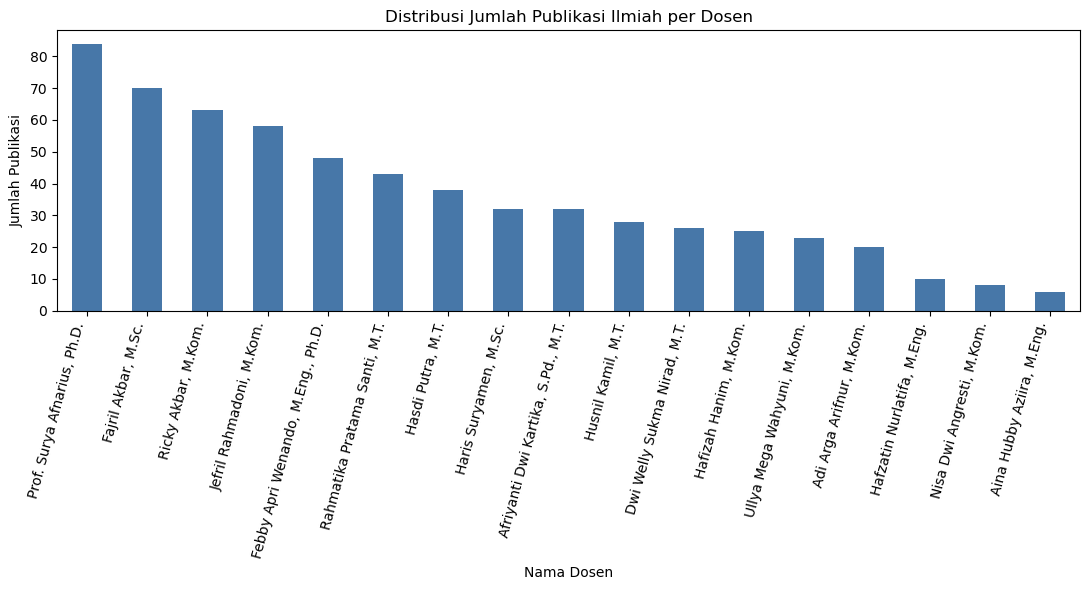

In [9]:
publikasi_per_dosen = df_pub["nama_dosen"].value_counts().sort_values(ascending=False)
ax = publikasi_per_dosen.plot(kind="bar", color="#4777a8")
ax.set_title("Distribusi Jumlah Publikasi Ilmiah per Dosen")
ax.set_xlabel("Nama Dosen")
ax.set_ylabel("Jumlah Publikasi")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

Kolom utama untuk kebutuhan SI-REKTA adalah `judul_publikasi` dan `nama_dosen`. Kolom `kelompok_keahlian` tersedia pada sumber publikasi, tetapi tidak digunakan sebagai fitur maupun dasar pencocokan rekomendasi dalam penelitian ini.

## 3.3 Analisis Gabungan Kedua Dataset

Sebelum integrasi, nama pembimbing pada dataset tugas akhir perlu dicocokkan dengan daftar dosen pada dataset publikasi. Pencocokan ini juga digunakan untuk membedakan dosen yang termasuk dalam cakupan kandidat sistem dan nama pembimbing yang tidak ditemukan pada dataset publikasi.

Variasi penulisan nama yang dapat dikenali diseragamkan menggunakan daftar alias eksplisit. Nama yang belum dapat dipastikan tidak dipaksakan untuk cocok dengan dosen tertentu.

In [10]:
# Daftar alias berdasarkan variasi penulisan yang ditemukan pada dataset tugas akhir.
alias_dosen = {
    "Prof. Surya Afnarius": "Prof. Surya Afnarius, Ph.D.",
    "Prof. Surya Afnarius, P.Hd": "Prof. Surya Afnarius, Ph.D.",
    "Prof. Surya Afnarius, Ph.D": "Prof. Surya Afnarius, Ph.D.",
    "Prof. Surya Afnarius, PhD": "Prof. Surya Afnarius, Ph.D.",
    "Prof.Surya Afnarius,Ph.D": "Prof. Surya Afnarius, Ph.D.",
    "Afriyanti Dwi Kartika, MT": "Afriyanti Dwi Kartika, S.Pd., M.T.",
    "Dwi Welly Sukma N, MT": "Dwi Welly Sukma Nirad, M.T.",
    "Hafizah Hanim, M.Kom": "Hafizah Hanim, M.Kom.",
    "Haris Suryamen, M.Sc": "Haris Suryamen, M.Sc.",
    "Hasdi Putra, MT": "Hasdi Putra, M.T.",
    "Husnil Kamil, MT": "Husnil Kamil, M.T.",
    "Jefril Ramadoni,M.Kom": "Jefril Rahmadoni, M.Kom.",
    "Rahmatika Pratama S, MT": "Rahmatika Pratama Santi, M.T.",
    "Rahmatika Pratama, MT": "Rahmatika Pratama Santi, M.T.",
    "Ricky Akbar, M.Kom": "Ricky Akbar, M.Kom.",
    "Ricky Akbar, M.Sc": "Ricky Akbar, M.Kom.",
    "Ricky Akbar, M.kom": "Ricky Akbar, M.Kom.",
    "Ullya Mega Wahyuni, M.Kom": "Ullya Mega Wahyuni, M.Kom.",
    "Aina Hubby Aziira, M.Eng": "Aina Hubby Aziira, M.Eng.",
    "Adi Arga Arifnur, M.Kom": "Adi Arga Arifnur, M.Kom.",
    "Fajril Akbar, M.Sc": "Fajril Akbar, M.Sc.",
    "Fajril Akbar, M.Kom": "Fajril Akbar, M.Sc."
}

def standardisasi_nama(nama):
    if pd.isna(nama):
        return None
    nama = str(nama).strip()
    if nama in ("", "-"):
        return None
    return alias_dosen.get(nama, nama)

daftar_dosen = set(df_pub["nama_dosen"].dropna().astype(str).str.strip().unique())

# Hitung hubungan judul TA dengan setiap pembimbing yang cocok dengan daftar dosen.
relasi_ta = []
for indeks, baris in df_ta.iterrows():
    for kolom in ["pembimbing_1", "pembimbing_2"]:
        nama_asli = baris.get(kolom)
        nama_baku = standardisasi_nama(nama_asli)
        if nama_baku in daftar_dosen:
            relasi_ta.append({
                "indeks_sumber": indeks,
                "judul_ta": baris["judul_ta"],
                "nama_dosen": nama_baku,
                "peran_pembimbing": kolom
            })

df_relasi_ta = pd.DataFrame(relasi_ta)
jumlah_ta_per_dosen = (
    df_relasi_ta.groupby("nama_dosen")["judul_ta"].count()
    if not df_relasi_ta.empty else pd.Series(dtype=int)
)
jumlah_pub_per_dosen = df_pub["nama_dosen"].value_counts()

ringkasan_gabungan = pd.DataFrame(index=sorted(daftar_dosen))
ringkasan_gabungan.index.name = "nama_dosen"
ringkasan_gabungan["riwayat_ta"] = jumlah_ta_per_dosen
ringkasan_gabungan["publikasi"] = jumlah_pub_per_dosen
ringkasan_gabungan = ringkasan_gabungan.fillna(0).astype(int)
ringkasan_gabungan["total_dokumen"] = (
    ringkasan_gabungan["riwayat_ta"] + ringkasan_gabungan["publikasi"]
)

print(f"Jumlah dosen pada dataset publikasi: {len(daftar_dosen)}")
print(f"Jumlah relasi judul TA–dosen yang cocok: {len(df_relasi_ta)}")
print(f"Jumlah judul TA unik yang memiliki minimal satu pembimbing cocok: {df_relasi_ta['judul_ta'].nunique()}")
print(f"Jumlah dosen dengan riwayat TA: {(ringkasan_gabungan['riwayat_ta'] > 0).sum()}")
print(f"Jumlah dosen tanpa riwayat TA: {(ringkasan_gabungan['riwayat_ta'] == 0).sum()}")
display(ringkasan_gabungan.sort_values("total_dokumen", ascending=False))

Jumlah dosen pada dataset publikasi: 17
Jumlah relasi judul TA–dosen yang cocok: 707
Jumlah judul TA unik yang memiliki minimal satu pembimbing cocok: 593
Jumlah dosen dengan riwayat TA: 14
Jumlah dosen tanpa riwayat TA: 3


,riwayat_ta,publikasi,total_dokumen
nama_dosen,,,
"Ricky Akbar, M.Kom.",155,63,218
"Prof. Surya Afnarius, Ph.D.",87,84,171
"Fajril Akbar, M.Sc.",74,70,144
"Husnil Kamil, M.T.",99,28,127
"Hasdi Putra, M.T.",72,38,110
"Haris Suryamen, M.Sc.",70,32,102
"Rahmatika Pratama Santi, M.T.",51,43,94
"Jefril Rahmadoni, M.Kom.",14,58,72
"Dwi Welly Sukma Nirad, M.T.",28,26,54


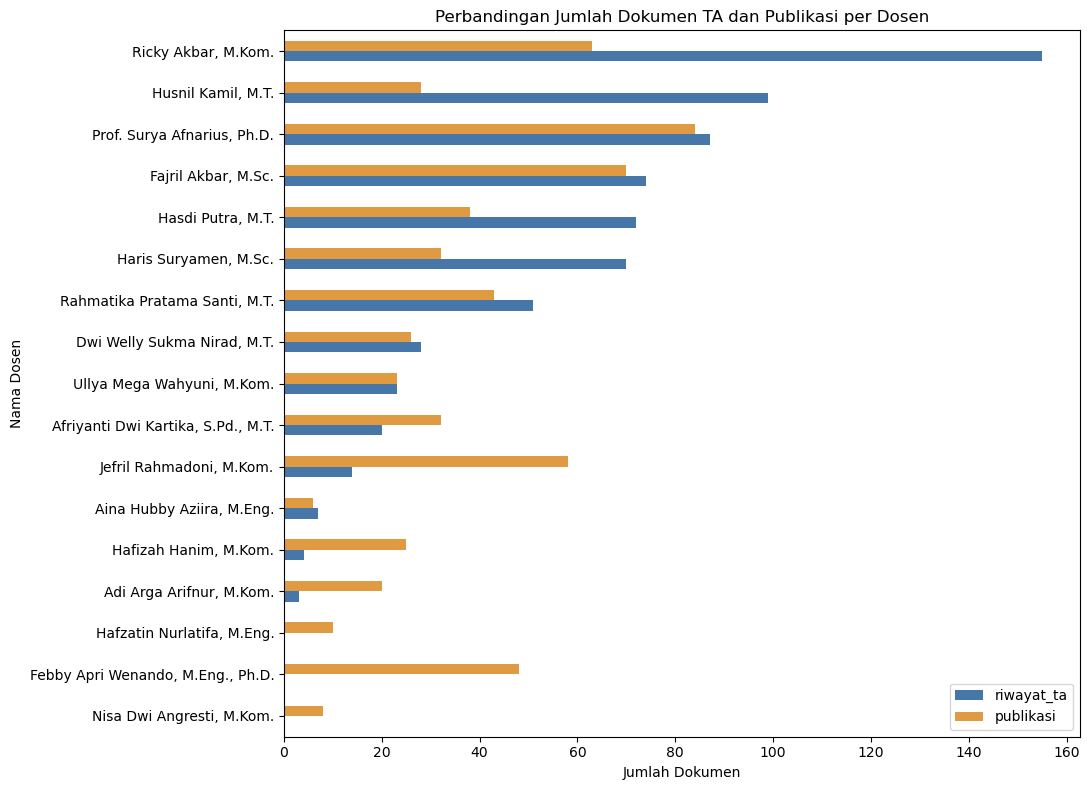

Ringkasan ketimpangan jumlah dokumen:
Jumlah dokumen paling sedikit per dosen: 8
Jumlah dokumen paling banyak per dosen : 218
Rasio maksimum terhadap minimum       : 27.25 kali


In [11]:
ax = ringkasan_gabungan[["riwayat_ta", "publikasi"]].sort_values(
    "riwayat_ta", ascending=True
).plot(kind="barh", figsize=(11, 8), color=["#4777a8", "#e09b42"])
ax.set_title("Perbandingan Jumlah Dokumen TA dan Publikasi per Dosen")
ax.set_xlabel("Jumlah Dokumen")
ax.set_ylabel("Nama Dosen")
plt.tight_layout()
plt.show()

print("Ringkasan ketimpangan jumlah dokumen:")
print(f"Jumlah dokumen paling sedikit per dosen: {ringkasan_gabungan['total_dokumen'].min()}")
print(f"Jumlah dokumen paling banyak per dosen : {ringkasan_gabungan['total_dokumen'].max()}")
print(f"Rasio maksimum terhadap minimum       : {(ringkasan_gabungan['total_dokumen'].max() / ringkasan_gabungan['total_dokumen'].min()):.2f} kali")

**Interpretasi hasil analisis gabungan:** dataset publikasi memuat 17 dosen. Ketika kolom pembimbing pertama dan kedua diperiksa, riwayat tugas akhir yang dapat dihubungkan dengan dosen dalam daftar tersebut berjumlah lebih banyak dibandingkan jika hanya pembimbing pertama yang digunakan. Karena satu tugas akhir dapat memiliki dua pembimbing, satu judul dapat membentuk lebih dari satu relasi judul–dosen.

Dosen yang tidak memiliki riwayat bimbingan pada data tugas akhir tetap memiliki publikasi ilmiah sebagai sumber informasi. Namun, jumlah dokumen gabungan antar-dosen masih berbeda cukup jauh. Perbedaan ini perlu diperhatikan saat pembentukan profil dosen pada tahap berikutnya dan tidak diselesaikan dengan menggandakan atau menghapus dokumen secara sembarangan.

# 4. Data Preprocessing

Tahap Data Preprocessing bertujuan menyiapkan kedua dataset agar memiliki struktur dan format yang konsisten, kemudian mengintegrasikannya menjadi satu dataset. Dataset akhir mempertahankan satu baris untuk setiap dokumen yang terkait dengan dosen.

Dalam proses ini, cakupan kandidat dosen mengikuti nama dosen yang tersedia pada dataset publikasi. Riwayat tugas akhir dari pembimbing yang tidak termasuk dalam daftar tersebut tidak dimasukkan ke korpus rekomendasi, tetapi jumlah dan nama yang dikecualikan tetap diperiksa agar prosesnya transparan.

## 4.1 Data Cleaning

Tahap pembersihan data dilakukan pada salinan dataset untuk menindaklanjuti temuan langsung pada **Bab 3 (Data Analysis / EDA)**:

1. **Normalisasi Placeholder Nilai Kosong (`"-"` $\rightarrow$ `NaN`):** Mengubah tanda strip `"-"` dan string kosong pada kolom identitas pembimbing serta metadata menjadi `NaN` standar.
2. **Penghapusan Baris TA Tanpa Pembimbing:** Mengeluarkan baris tugas akhir yang tidak memiliki `pembimbing_1` maupun `pembimbing_2` sama sekali karena tidak dapat dikaitkan ke profil dosen mana pun.
3. **Pembersihan Ekor Sitasi Jurnal pada Judul Publikasi:** Menghapus tempelan nama jurnal, volume/edisi, dan nomor halaman di akhir `judul_publikasi` (misalnya `. Nama Jurnal, 6 (2), 294-304`) agar teks kembali menjadi judul murni.
4. **Penghapusan Artefak Singkatan Jurnal & Duplikasi Pasca-Pembersihan:** Mengeluarkan entri 1 kata tanpa tahun (`tahun = NaN`) yang teridentifikasi berasal dari akronim nama jurnal pada sitasi (seperti `"JMKSP"`), **tanpa menghapus judul monograf/topik keilmuan 1 kata yang sah dan bertahun jelas seperti `"GIS"`**. Selanjutnya, duplikasi judul publikasi (*case-insensitive*) pada dosen yang sama dihapus.

In [12]:
ta_work = df_ta.copy()
pub_work = df_pub.copy()

jumlah_ta_awal = len(ta_work)
jumlah_pub_awal = len(pub_work)

# 1. Rapikan spasi dan konversi placeholder '-' / string kosong menjadi NaN standar.
jumlah_strip_pembimbing = sum(
    ta_work[kol].astype(str).str.strip().eq("-").sum()
    for kol in ["pembimbing_1", "pembimbing_2"]
)
for kolom in ["judul_ta", "pembimbing_1", "pembimbing_2"]:
    ta_work[kolom] = ta_work[kolom].apply(lambda x: x.strip() if isinstance(x, str) else x)
    ta_work[kolom] = ta_work[kolom].replace({"": np.nan, "-": np.nan})

for kolom in ["judul_publikasi", "nama_dosen", "tahun"]:
    if kolom in pub_work.columns:
        pub_work[kolom] = pub_work[kolom].apply(lambda x: x.strip() if isinstance(x, str) else x)
        pub_work[kolom] = pub_work[kolom].replace({"": np.nan, "-": np.nan})

# 2. Keluarkan baris TA tanpa judul atau tanpa pembimbing sama sekali (pembimbing_1 & pembimbing_2 kosong).
ta_work = ta_work.dropna(subset=["judul_ta"])
mask_ta_tanpa_pembimbing = ta_work["pembimbing_1"].isna() & ta_work["pembimbing_2"].isna()
jumlah_ta_tanpa_pembimbing = int(mask_ta_tanpa_pembimbing.sum())
ta_work = ta_work[~mask_ta_tanpa_pembimbing].reset_index(drop=True)

# 3. Bersihkan ekor sitasi jurnal, volume, dan halaman pada judul publikasi.
pub_work = pub_work.dropna(subset=["judul_publikasi", "nama_dosen"]).copy()
pola_sitasi = re.compile(r"\.\s+[^.]+,\s*\d+\s*\(\d+\),\s*\d+\s*[-–]\s*\d+\s*$")
mask_ekor_sitasi = pub_work["judul_publikasi"].str.contains(pola_sitasi, na=False)
jumlah_ekor_sitasi = int(mask_ekor_sitasi.sum())

teks_ekor_jurnal = " ".join(
    pub_work.loc[mask_ekor_sitasi, "judul_publikasi"].apply(
        lambda s: pola_sitasi.search(s).group(0).lower()
    )
)
pub_work.loc[mask_ekor_sitasi, "judul_publikasi"] = pub_work.loc[
    mask_ekor_sitasi, "judul_publikasi"
].apply(lambda s: pola_sitasi.sub("", s).strip())

# 4. Keluarkan artefak akronim nama jurnal (1 kata, tahun kosong, muncul di ekor sitasi jurnal),
#    namun pertahankan topik keilmuan 1 kata yang valid seperti 'GIS'.
mask_artefak_jurnal = (
    (pub_work["judul_publikasi"].str.split().str.len() == 1)
    & (pub_work["tahun"].isna())
    & (pub_work["judul_publikasi"].str.lower().apply(lambda w: w in teks_ekor_jurnal))
)
jumlah_artefak_jurnal = int(mask_artefak_jurnal.sum())
pub_work = pub_work[~mask_artefak_jurnal].reset_index(drop=True)

# 5. Hapus duplikasi judul publikasi (case-insensitive) pada dosen yang sama pasca-pembersihan sitasi.
pub_work["_judul_norm"] = pub_work["judul_publikasi"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
jumlah_sebelum_dedup_pub = len(pub_work)
pub_work = pub_work.drop_duplicates(subset=["nama_dosen", "_judul_norm"], keep="first").drop(columns=["_judul_norm"]).reset_index(drop=True)
jumlah_duplikat_pub = jumlah_sebelum_dedup_pub - len(pub_work)

print(f"Baris TA awal                                      : {jumlah_ta_awal}")
print(f"Placeholder '-' pada pembimbing dinormalisasi ke NaN: {jumlah_strip_pembimbing}")
print(f"Baris TA tanpa pembimbing yang dikeluarkan         : {jumlah_ta_tanpa_pembimbing}")
print(f"Baris TA bersih tersisa                            : {len(ta_work)}")
print("-" * 60)
print(f"Baris publikasi awal                               : {jumlah_pub_awal}")
print(f"Judul publikasi yang dibersihkan ekor sitasinya    : {jumlah_ekor_sitasi}")
print(f"Baris artefak nama jurnal ('JMKSP') dikeluarkan    : {jumlah_artefak_jurnal}")
print(f"Duplikat publikasi tersembunyi yang dihapus        : {jumlah_duplikat_pub}")
print(f"Baris publikasi bersih tersisa                     : {len(pub_work)}")
print(f"Verifikasi judul topik 1 kata 'GIS' tetap terjaga  : {(pub_work['judul_publikasi'] == 'GIS').any()}")

Baris TA awal                                      : 625
Placeholder '-' pada pembimbing dinormalisasi ke NaN: 458
Baris TA tanpa pembimbing yang dikeluarkan         : 2
Baris TA bersih tersisa                            : 623
------------------------------------------------------------
Baris publikasi awal                               : 614
Judul publikasi yang dibersihkan ekor sitasinya    : 2
Baris artefak nama jurnal ('JMKSP') dikeluarkan    : 1
Duplikat publikasi tersembunyi yang dihapus        : 1
Baris publikasi bersih tersisa                     : 612
Verifikasi judul topik 1 kata 'GIS' tetap terjaga  : True


## 4.2 Data Standardization

Nama dosen pada dataset tugas akhir diseragamkan menggunakan alias yang telah diperiksa pada tahap analisis. Setelah itu, nama pembimbing dicocokkan dengan daftar dosen pada dataset publikasi. Kedua kolom pembimbing diperiksa agar riwayat dari pembimbing pertama maupun kedua dapat dipertahankan jika sesuai dengan cakupan sistem.

In [13]:
daftar_dosen = set(pub_work["nama_dosen"].dropna().astype(str).str.strip().unique())

# Bentuk satu baris relasi untuk setiap pasangan judul TA dan dosen yang cocok.
baris_ta = []
nama_tidak_cocok = []

for indeks, baris in ta_work.iterrows():
    for kolom in ["pembimbing_1", "pembimbing_2"]:
        nama_asli = baris[kolom]
        nama_baku = standardisasi_nama(nama_asli)
        if nama_baku is None:
            continue
        if nama_baku in daftar_dosen:
            baris_ta.append({
                "nama_dosen": nama_baku,
                "judul_dokumen": baris["judul_ta"],
                "jenis_dokumen": "tugas_akhir"
            })
        else:
            nama_tidak_cocok.append(str(nama_asli).strip())

ta_dokumen = pd.DataFrame(
    baris_ta,
    columns=["nama_dosen", "judul_dokumen", "jenis_dokumen"]
)

# Nama dosen publikasi mengikuti identitas pada sumber publikasi setelah spasi dirapikan.
publikasi_dokumen = pd.DataFrame({
    "nama_dosen": pub_work["nama_dosen"].astype(str).str.strip(),
    "judul_dokumen": pub_work["judul_publikasi"].astype(str).str.strip(),
    "jenis_dokumen": "publikasi"
})

print(f"Relasi dokumen tugas akhir yang cocok : {len(ta_dokumen)}")
print(f"Dokumen publikasi yang dipertahankan : {len(publikasi_dokumen)}")
print(f"Variasi nama pembimbing tidak cocok  : {len(set(nama_tidak_cocok))}")
print("Nama yang tidak cocok:")
display(pd.Series(sorted(set(nama_tidak_cocok)), name="Nama Pembimbing Tidak Cocok").to_frame())

Relasi dokumen tugas akhir yang cocok : 707
Dokumen publikasi yang dipertahankan : 612
Variasi nama pembimbing tidak cocok  : 7
Nama yang tidak cocok:


,Nama Pembimbing Tidak Cocok
0,"Alizar Hasan, Ph.D"
1,"Difana Meilani, MISD"
2,"Difana Meilani, MSID"
3,"Dr. Wahyudi, MT"
4,"Hafid Yoza Putra, MT"
5,"Meza Silvana, MT"
6,"Syafii, Ph.D"


Nama pembimbing yang tidak ditemukan pada daftar dosen publikasi tidak dipaksakan untuk dipetakan. Dengan demikian, dokumen tugas akhir yang masuk ke dataset SI-REKTA hanya dikaitkan dengan dosen yang identitasnya dapat dicocokkan secara eksplisit. Daftar nama yang tidak cocok ditampilkan sebagai catatan audit.

## 4.3 Text Preprocessing

Pembersihan teks dilakukan pada judul tugas akhir dan publikasi. Proses mencakup perubahan huruf menjadi lowercase, penghapusan URL, penggantian tanda baca atau simbol dengan spasi, serta perapian spasi berlebih.

Selain pembersihan dasar, tahap ini mengimplementasikan metode **Hybrid Domain-Specific Academic Stopwords**. Kamus stopword dirancang secara bertingkat untuk menyaring:
1. **Preposisi dan konjungsi dwibahasa** (Indonesia & Inggris: *dan, di, dari, for, with, about, etc.*).
2. **Templat prosedural dan kata kerja seremonial skripsi** (*pembangunan, rancang bangun, berbasis web, studi kasus, implementasi, analisis, etc.*).
3. **Entitas institusi, lokasi, dan istilah payung umum jurusan** (*sistem, informasi, universitas andalas, padang, dinas, pt, etc.*).

Dengan penyaringan ini, istilah teknis substantif dan topik keahlian murni dipertahankan tanpa terdistorsi oleh derau administratif.

In [14]:
# Kamus Hybrid Domain-Specific Academic Stopwords
ACADEMIC_STOPWORDS = {
    # 1. Preposisi, Konjungsi & Kata Hubung (ID & EN)
    "dan", "di", "ke", "dari", "pada", "untuk", "dengan", "dalam", "yang", 
    "terhadap", "tentang", "atau", "oleh", "sebagai", "ini", "itu", "bagi",
    "of", "in", "the", "and", "for", "on", "with", "by", "at", "to", "from", 
    "as", "an", "a", "is", "are", "into", "through", "about", "via", "towards",

    # 2. Templat Prosedural & Kata Kerja Skripsi (ID & EN)
    "pembangunan", "rancang", "bangun", "pengembangan", "pembuatan", "perancangan",
    "penerapan", "implementasi", "analisis", "analisa", "evaluasi", "pemodelan",
    "menggunakan", "metode", "berbasis", "studi", "kasus", "fitur", "aplikasi",
    "using", "based", "study", "case", "analysis", "approach", "implementation", 
    "development", "evaluation", "design", "review",

    # 3. Entitas Institusi, Lokasi, dan Istilah Umum Jurusan
    "sistem", "informasi", "system", "information",
    "universitas", "andalas", "unand", "fakultas", "teknologi", "jurusan", "departemen",
    "padang", "kota", "provinsi", "sumatera", "barat", "indonesia",
    "dinas", "pt", "cv", "kantor", "instansi"
}

def bersihkan_teks(teks):
    if pd.isna(teks):
        return ""
    teks = str(teks).lower()
    # Hapus URL
    teks = re.sub(r"https?://\S+|www\.\S+", " ", teks)
    # Hapus karakter non-alfanumerik dan tanda baca
    teks = re.sub(r"[^\w\s]", " ", teks, flags=re.UNICODE)
    teks = teks.replace("_", " ")
    
    # Filter token: buang stopword dan kata dengan panjang <= 1 huruf
    tokens = [t for t in teks.split() if t not in ACADEMIC_STOPWORDS and len(t) > 1]
    return " ".join(tokens)

ta_dokumen["teks_dokumen"] = ta_dokumen["judul_dokumen"].apply(bersihkan_teks)
publikasi_dokumen["teks_dokumen"] = publikasi_dokumen["judul_dokumen"].apply(bersihkan_teks)

# Keluarkan dokumen yang 100% hanya berisi kata umum/stopword tanpa kata kunci topik spesifik.
ta_kosong_topik = int((ta_dokumen["teks_dokumen"] == "").sum())
pub_kosong_topik = int((publikasi_dokumen["teks_dokumen"] == "").sum())

if pub_kosong_topik > 0:
    print(f"Judul publikasi tanpa token topik spesifik yang dikeluarkan ({pub_kosong_topik} baris):")
    display(publikasi_dokumen[publikasi_dokumen["teks_dokumen"] == ""][["nama_dosen", "judul_dokumen"]])

ta_dokumen = ta_dokumen[ta_dokumen["teks_dokumen"] != ""].reset_index(drop=True)
publikasi_dokumen = publikasi_dokumen[publikasi_dokumen["teks_dokumen"] != ""].reset_index(drop=True)

print("Contoh pembersihan judul tugas akhir:")
display(ta_dokumen[["judul_dokumen", "teks_dokumen"]].head(5))
print("Contoh pembersihan judul publikasi:")
display(publikasi_dokumen[["judul_dokumen", "teks_dokumen"]].head(5))

Judul publikasi tanpa token topik spesifik yang dikeluarkan (2 baris):


,nama_dosen,judul_dokumen
12,"Prof. Surya Afnarius, Ph.D.",Perancangan Sistem
20,"Prof. Surya Afnarius, Ph.D.",Implementasi Sistem


Contoh pembersihan judul tugas akhir:


,judul_dokumen,teks_dokumen
0,Pembangunan Aplikasi Mobile GIS Wisata Sejarah Provinsi Sumatera Barat,mobile gis wisata sejarah
1,Pembangunan Aplikasi Mobile Geographic Information system Hotel di Sumatera Barat,mobile geographic hotel
2,Pembangunan Aplikasi Mobile Gis Pariwisata : Event di Provinsi Sumatera Barat,mobile gis pariwisata event
3,Pembangunan Aplikasi Mobile GIS Wisata Alam Provinsi Sumatera Barat,mobile gis wisata alam
4,Pembangunan Aplikasi Mobile Geographic Information System Wisata Kuliner Sumatera Barat,mobile geographic wisata kuliner


Contoh pembersihan judul publikasi:


,judul_dokumen,teks_dokumen
0,Developing web-based and mobile-based GIS for places of worship information to support halal tou...,developing web mobile gis places worship support halal tourism bukittinggi
1,"Development of GIS for buildings in the customary village of minangkabau koto gadang, west Sumat...",gis buildings customary village minangkabau koto gadang west sumatra
2,Pengembangan Aplikasi Web GIS Pariwisata Backpacker,web gis pariwisata backpacker
3,Pembangunan aplikasi wisata kuliner Sumbar berbasis mobile geographic information system,wisata kuliner sumbar mobile geographic
4,Digitalisasi tourism,digitalisasi tourism


Pembersihan ini menerapkan penyaringan kata henti akademik (*hybrid domain-specific academic stopwords*), namun secara sengaja **tidak melakukan stemming** maupun penerjemahan otomatis. Istilah teknis berbahasa Indonesia dan Inggris dipertahankan dalam bentuk kata aslinya yang utuh agar tidak terjadi pemotongan imbuhan (*over-stemming*) yang dapat merusak makna istilah teknologi informasi (seperti *clustering*, *framework*, *database*, *intelligence*).

## 4.4 Data Integration

Kedua dataset yang telah disiapkan digabungkan secara vertikal (*concatenation*). Setiap baris mewakili satu dokumen yang dikaitkan dengan satu dosen. Jika sebuah judul tugas akhir memiliki dua pembimbing yang termasuk dalam cakupan sistem, judul tersebut akan muncul pada dua baris dengan identitas dosen yang berbeda.

In [15]:
kolom_utama = ["nama_dosen", "judul_dokumen", "jenis_dokumen", "teks_dokumen"]

df_sirekta = pd.concat(
    [ta_dokumen[kolom_utama], publikasi_dokumen[kolom_utama]],
    ignore_index=True
)

# Hapus hanya duplikasi dokumen pada dosen dan sumber yang sama.
jumlah_sebelum_duplikat = len(df_sirekta)
df_sirekta = df_sirekta.drop_duplicates(
    subset=["nama_dosen", "judul_dokumen", "jenis_dokumen"]
).reset_index(drop=True)

print(f"Jumlah baris sebelum pemeriksaan duplikasi: {jumlah_sebelum_duplikat}")
print(f"Jumlah duplikasi yang dihapus             : {jumlah_sebelum_duplikat - len(df_sirekta)}")
print(f"Jumlah baris setelah integrasi             : {len(df_sirekta)}")
display(df_sirekta.head(10))

Jumlah baris sebelum pemeriksaan duplikasi: 1317
Jumlah duplikasi yang dihapus             : 0
Jumlah baris setelah integrasi             : 1317


,nama_dosen,judul_dokumen,jenis_dokumen,teks_dokumen
0,"Prof. Surya Afnarius, Ph.D.",Pembangunan Aplikasi Mobile GIS Wisata Sejarah Provinsi Sumatera Barat,tugas_akhir,mobile gis wisata sejarah
1,"Prof. Surya Afnarius, Ph.D.",Pembangunan Aplikasi Mobile Geographic Information system Hotel di Sumatera Barat,tugas_akhir,mobile geographic hotel
2,"Prof. Surya Afnarius, Ph.D.",Pembangunan Aplikasi Mobile Gis Pariwisata : Event di Provinsi Sumatera Barat,tugas_akhir,mobile gis pariwisata event
3,"Prof. Surya Afnarius, Ph.D.",Pembangunan Aplikasi Mobile GIS Wisata Alam Provinsi Sumatera Barat,tugas_akhir,mobile gis wisata alam
4,"Prof. Surya Afnarius, Ph.D.",Pembangunan Aplikasi Mobile Geographic Information System Wisata Kuliner Sumatera Barat,tugas_akhir,mobile geographic wisata kuliner
5,"Prof. Surya Afnarius, Ph.D.",Pembangunan Aplikasi Mobile Geographic Information System Wisata Buatan Sumatera Barat,tugas_akhir,mobile geographic wisata buatan
6,"Prof. Surya Afnarius, Ph.D.",Pembangunan Aplikasi Mobile GIS Wisata Islam Sumatera Barat,tugas_akhir,mobile gis wisata islam
7,"Husnil Kamil, M.T.",Sistem Informasi Logistik Aktiva Tetap Berbasis Web dengan Fiture Mobile pada PT. Bank Rakyat In...,tugas_akhir,logistik aktiva tetap web fiture mobile bank rakyat persero tbk cabang panjang
8,"Husnil Kamil, M.T.",Sistem Informasi Manajemen Aset Tetap Berwujud Berbasis Web dengan Fitur Mobile pada PDAM Kota P...,tugas_akhir,manajemen aset tetap berwujud web mobile pdam
9,"Prof. Surya Afnarius, Ph.D.",Pembangunan Sistem Informasi Geografis (SIG) mobile fasilitas Umum Pariwisata dan SPBU Sumatera ...,tugas_akhir,geografis sig mobile fasilitas umum pariwisata spbu


## 4.5 Pemeriksaan Dataset Akhir

Pemeriksaan akhir dilakukan untuk memastikan dataset telah memiliki kolom utama yang dibutuhkan, tidak memiliki nilai kosong pada kolom penting, serta tetap menyimpan dokumen dari kedua sumber.

In [16]:
ringkasan_akhir = pd.DataFrame({
    "Keterangan": [
        "Jumlah dokumen",
        "Jumlah dosen unik",
        "Dokumen tugas akhir",
        "Dokumen publikasi",
        "Missing nama dosen",
        "Missing judul dokumen",
        "Missing teks dokumen",
        "Duplikasi berdasarkan dosen, judul, dan jenis"
    ],
    "Nilai": [
        len(df_sirekta),
        df_sirekta["nama_dosen"].nunique(),
        (df_sirekta["jenis_dokumen"] == "tugas_akhir").sum(),
        (df_sirekta["jenis_dokumen"] == "publikasi").sum(),
        df_sirekta["nama_dosen"].isna().sum(),
        df_sirekta["judul_dokumen"].isna().sum(),
        df_sirekta["teks_dokumen"].isna().sum(),
        df_sirekta.duplicated(["nama_dosen", "judul_dokumen", "jenis_dokumen"]).sum()
    ]
})
display(ringkasan_akhir)

,Keterangan,Nilai
0,Jumlah dokumen,1317
1,Jumlah dosen unik,17
2,Dokumen tugas akhir,707
3,Dokumen publikasi,610
4,Missing nama dosen,0
5,Missing judul dokumen,0
6,Missing teks dokumen,0
7,"Duplikasi berdasarkan dosen, judul, dan jenis",0


In [17]:
distribusi_jenis = df_sirekta["jenis_dokumen"].value_counts().rename_axis("Jenis Dokumen").reset_index(name="Jumlah")
display(distribusi_jenis)

distribusi_dosen = (
    df_sirekta.groupby(["nama_dosen", "jenis_dokumen"])
    .size()
    .unstack(fill_value=0)
)
for kolom in ["tugas_akhir", "publikasi"]:
    if kolom not in distribusi_dosen.columns:
        distribusi_dosen[kolom] = 0
distribusi_dosen["total_dokumen"] = distribusi_dosen["tugas_akhir"] + distribusi_dosen["publikasi"]
distribusi_dosen = distribusi_dosen.sort_values("total_dokumen", ascending=False)
display(distribusi_dosen)

,Jenis Dokumen,Jumlah
0,tugas_akhir,707
1,publikasi,610


jenis_dokumen,publikasi,tugas_akhir,total_dokumen
nama_dosen,,,
"Ricky Akbar, M.Kom.",63,155,218
"Prof. Surya Afnarius, Ph.D.",82,87,169
"Fajril Akbar, M.Sc.",70,74,144
"Husnil Kamil, M.T.",28,99,127
"Hasdi Putra, M.T.",38,72,110
"Haris Suryamen, M.Sc.",32,70,102
"Rahmatika Pratama Santi, M.T.",43,51,94
"Jefril Rahmadoni, M.Kom.",56,14,70
"Dwi Welly Sukma Nirad, M.T.",26,28,54


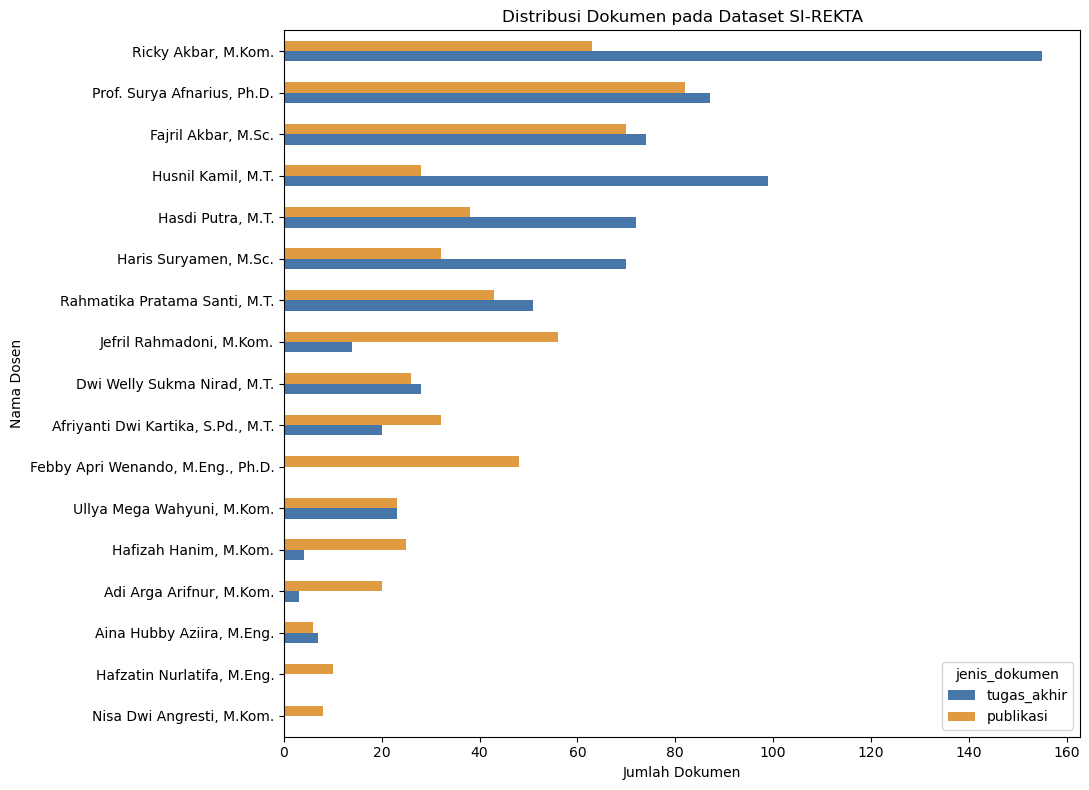

In [18]:
ax = distribusi_dosen.sort_values("total_dokumen", ascending=True)[["tugas_akhir", "publikasi"]].plot(kind="barh", figsize=(11, 8), color=["#4777a8", "#e09b42"])
ax.set_title("Distribusi Dokumen pada Dataset SI-REKTA")
ax.set_xlabel("Jumlah Dokumen")
ax.set_ylabel("Nama Dosen")
plt.tight_layout()
plt.show()

## 4.6 Penyimpanan Dataset Hasil Preprocessing

Dataset hasil integrasi disimpan dalam format CSV agar dapat digunakan pada tahap berikutnya. File ini memuat empat kolom utama: `nama_dosen`, `judul_dokumen`, `jenis_dokumen`, dan `teks_dokumen`.

In [19]:
output_path = Path("Dataset_SI_REKTA_Preprocessed.csv")
df_sirekta.to_csv(output_path, index=False, encoding="utf-8-sig")

print(f"Dataset hasil preprocessing tersimpan di: {output_path.resolve()}")
print(f"Ukuran dataset akhir: {df_sirekta.shape[0]} baris × {df_sirekta.shape[1]} kolom")

Dataset hasil preprocessing tersimpan di: /Users/farrelgr/SI-REKTA/docs/Dataset_SI_REKTA_Preprocessed.csv
Ukuran dataset akhir: 1317 baris × 4 kolom


## Kesimpulan Tahap Data Preprocessing

Dua dataset telah dibersihkan, diseragamkan, dan diintegrasikan menjadi satu dataset dengan satu baris untuk setiap dokumen yang terkait dengan dosen. Dokumen tugas akhir yang memiliki dua pembimbing dapat menghasilkan lebih dari satu relasi dosen–dokumen, sedangkan publikasi dikaitkan langsung dengan nama dosen pada sumbernya.

Dataset akhir menjadi masukan untuk tahap berikutnya, yaitu pembentukan representasi teks menggunakan TF-IDF dan penyusunan profil dosen. Perbedaan jumlah dokumen antar-dosen tetap dipertahankan sebagai kondisi data dan perlu dipertimbangkan saat profil dosen dibentuk.

# 5. Data Processing Procedures

Tahap *Data Processing Procedures* mengubah dataset hasil preprocessing menjadi struktur data yang dapat digunakan untuk melatih dan menguji model rekomendasi. Tahapan meliputi pemeriksaan data masukan, pembentukan kelompok judul TA, pembagian judul TA menjadi training dan testing, penggabungan seluruh publikasi ke training, pembentukan profil dosen, serta transformasi teks menggunakan TF-IDF.

Pembagian dilakukan hanya pada judul TA unik. Satu judul yang terhubung dengan lebih dari satu dosen diperlakukan sebagai satu kelompok agar seluruh relasinya berada pada subset yang sama. Seluruh publikasi dosen dipertahankan pada training sebagai sumber informasi tambahan untuk memperkaya profil dosen.


## 5.1 Persiapan Dataset dan Identitas Dokumen

Dataset `df_sirekta` dari tahap preprocessing menjadi masukan utama. Identitas dokumen dibentuk dari teks judul yang telah dibersihkan. Pengelompokan berdasarkan judul mencegah judul yang sama, termasuk judul tugas akhir dengan dua pembimbing, tersebar ke subset yang berbeda.

Kolom `jenis_dokumen` tetap dipertahankan untuk memastikan sumber tugas akhir dan publikasi dapat diperiksa secara terpisah.

In [20]:
# Salin dataset hasil preprocessing dan pastikan kolom utama tersedia.
kolom_wajib = ["nama_dosen", "judul_dokumen", "jenis_dokumen", "teks_dokumen"]
data_model = df_sirekta[kolom_wajib].copy()

# Hapus baris yang tidak memiliki identitas dosen atau teks yang dapat diproses.
data_model = data_model.dropna(subset=["nama_dosen", "teks_dokumen"]).copy()
data_model["nama_dosen"] = data_model["nama_dosen"].astype(str).str.strip()
data_model["teks_dokumen"] = data_model["teks_dokumen"].astype(str).str.strip()
data_model = data_model[
    (data_model["nama_dosen"] != "") &
    (data_model["teks_dokumen"] != "")
].copy()

# Bentuk identitas kelompok dari judul yang sudah dibersihkan.
# Identitas tidak memasukkan nama dosen agar judul dengan beberapa pembimbing tetap satu kelompok.
data_model["id_dokumen"] = data_model["teks_dokumen"].str.lower().str.strip()

# Hapus duplikasi relasi yang sama agar satu dosen tidak menerima judul identik berulang dari sumber sama.
data_model = data_model.drop_duplicates(
    subset=["nama_dosen", "id_dokumen", "jenis_dokumen"]
).reset_index(drop=True)

print(f"Jumlah relasi dokumen-dosen: {len(data_model)}")
print(f"Jumlah judul/dokumen unik   : {data_model['id_dokumen'].nunique()}")
print(f"Jumlah dosen                : {data_model['nama_dosen'].nunique()}")
display(data_model.groupby("jenis_dokumen").size().rename("Jumlah_dokumen").to_frame())


Jumlah relasi dokumen-dosen: 1317
Jumlah judul/dokumen unik   : 1043
Jumlah dosen                : 17


,Jumlah_dokumen
jenis_dokumen,
publikasi,610
tugas_akhir,707


## 5.2 Train-Test Split Khusus Judul Tugas Akhir

Pembagian data training dan testing hanya dilakukan terhadap dokumen berjenis `tugas_akhir`, dengan target proporsi 80% training dan 20% testing berdasarkan judul TA unik yang layak diuji. Pembagian dilakukan pada tingkat `id_dokumen` agar satu judul TA yang memiliki lebih dari satu pembimbing tidak tersebar ke subset yang berbeda.

Seluruh dokumen berjenis `publikasi` langsung dimasukkan ke data training dan digunakan untuk memperkaya profil dosen. Sebelum memilih data testing, notebook memeriksa kesamaan judul TA dengan judul publikasi. Judul TA yang identik dengan publikasi tidak dijadikan kueri testing karena publikasi tersebut sudah tersedia pada training dan dapat menyebabkan kebocoran informasi. Judul TA tersebut tetap berada pada training.

Pemilihan judul TA testing dilakukan secara acak dengan seed tetap (`RANDOM_STATE = 42`). Proses pemilihan mempertahankan minimal satu judul TA training bagi setiap dosen. Oleh karena itu, proporsi testing secara keseluruhan diupayakan mendekati 20%, tetapi distribusi testing pada masing-masing dosen tidak harus tepat 20%. Jika pembatasan minimal satu judul training menyebabkan target tidak tercapai, jumlah aktual akan ditampilkan.

Proporsi 80:20 berlaku untuk judul TA unik yang tidak identik dengan publikasi, bukan untuk keseluruhan dokumen gabungan. Jumlah publikasi training selalu 100% dan jumlah publikasi testing harus nol.


In [21]:
# Tetapkan proporsi dan seed agar pembagian dapat direproduksi.
PROPORSI_TEST = 0.20
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Pisahkan sumber data sebelum melakukan train-test split.
data_ta = data_model[data_model["jenis_dokumen"] == "tugas_akhir"].copy()
data_publikasi = data_model[data_model["jenis_dokumen"] == "publikasi"].copy()

if data_ta.empty:
    raise ValueError("Data tugas akhir kosong sehingga pembagian training dan testing tidak dapat dilakukan.")
if data_publikasi.empty:
    raise ValueError("Data publikasi kosong. Periksa kembali dataset publikasi dosen.")

# Kelompokkan judul TA unik dan daftar dosen pembimbingnya.
kelompok_ta = data_ta.groupby("id_dokumen")["nama_dosen"].apply(
    lambda x: tuple(sorted(set(x)))
)

# Hindari judul TA testing yang identik dengan judul publikasi pada training.
# Seluruh publikasi tetap berada pada training, sehingga judul yang sama tidak boleh menjadi kueri testing.
id_publikasi = set(data_publikasi["id_dokumen"].unique())
id_ta_unik = set(data_ta["id_dokumen"].unique())
id_ta_sama_dengan_publikasi = id_ta_unik.intersection(id_publikasi)
kandidat_ta = np.array(sorted(id_ta_unik - id_publikasi), dtype=object)

if len(kandidat_ta) == 0:
    raise ValueError("Tidak ada judul TA yang dapat dijadikan testing setelah pemeriksaan kesamaan dengan publikasi.")

rng.shuffle(kandidat_ta)

# Target 20% dihitung dari judul TA yang layak diuji, yaitu yang tidak identik dengan publikasi.
jumlah_target_ta_test = int(np.ceil(len(kandidat_ta) * PROPORSI_TEST))
total_ta_per_dosen = data_ta.groupby("nama_dosen")["id_dokumen"].nunique().to_dict()
jumlah_test_ta_per_dosen = {nama: 0 for nama in total_ta_per_dosen}
kelompok_ta_test = set()

# Pilih judul secara acak, tetapi sisakan minimal satu judul TA training bagi setiap dosen.
for id_dokumen in kandidat_ta:
    if len(kelompok_ta_test) >= jumlah_target_ta_test:
        break

    dosen_terkait = kelompok_ta.loc[id_dokumen]
    if any(
        jumlah_test_ta_per_dosen[nama] + 1 >= total_ta_per_dosen[nama]
        for nama in dosen_terkait
    ):
        continue

    kelompok_ta_test.add(id_dokumen)
    for nama in dosen_terkait:
        jumlah_test_ta_per_dosen[nama] += 1

if len(kelompok_ta_test) < jumlah_target_ta_test:
    print(
        "Peringatan: jumlah testing tidak mencapai target karena pembatasan "
        "minimal satu judul TA training untuk setiap dosen."
    )

# Seluruh publikasi masuk training; hanya judul TA terpilih yang masuk testing.
mask_ta_test = data_ta["id_dokumen"].isin(kelompok_ta_test)
data_ta_test = data_ta.loc[mask_ta_test].copy()
data_ta_train = data_ta.loc[~mask_ta_test].copy()

df_train = pd.concat(
    [data_ta_train, data_publikasi],
    ignore_index=True
).reset_index(drop=True)
df_test = data_ta_test.reset_index(drop=True)

# Validasi pemisahan judul TA dan kelengkapan publikasi pada training.
id_train = set(df_train["id_dokumen"])
id_test = set(df_test["id_dokumen"])
irisan_train_test = id_train.intersection(id_test)

assert len(irisan_train_test) == 0, \
    "Ditemukan judul identik pada training dan testing, termasuk lintas sumber."
assert set(df_test["jenis_dokumen"].unique()) == {"tugas_akhir"}, \
    "Data testing harus hanya berisi judul tugas akhir."
assert (df_train["jenis_dokumen"] == "publikasi").sum() == len(data_publikasi), \
    "Seluruh publikasi harus tersedia pada data training."
assert (df_test["jenis_dokumen"] == "publikasi").sum() == 0, \
    "Publikasi tidak boleh masuk ke data testing."
assert set(data_model["nama_dosen"].unique()).issubset(set(df_train["nama_dosen"].unique())), \
    "Terdapat dosen yang tidak memiliki dokumen training."

print(f"Jumlah seluruh judul TA unik                  : {len(id_ta_unik)}")
print(f"Judul TA identik dengan publikasi (dikecualikan dari testing): {len(id_ta_sama_dengan_publikasi)}")
print(f"Jumlah kandidat judul TA testing              : {len(kandidat_ta)}")
print(f"Target judul TA testing                       : {jumlah_target_ta_test}")
print(f"Jumlah relasi TA training                     : {len(data_ta_train)}")
print(f"Jumlah relasi TA testing                      : {len(df_test)}")
print(f"Judul TA unik training                        : {data_ta_train['id_dokumen'].nunique()}")
print(f"Judul TA unik testing                         : {df_test['id_dokumen'].nunique()}")
print(f"Jumlah publikasi pada training                : {len(data_publikasi)}")
print(f"Jumlah publikasi pada testing                 : {(df_test['jenis_dokumen'] == 'publikasi').sum()}")
print(f"Jumlah seluruh dokumen training               : {len(df_train)}")
print(f"Irisan judul identik train-test               : {len(irisan_train_test)}")
print(f"Proporsi testing dari kandidat TA             : {len(id_test) / len(kandidat_ta):.2%}")

Jumlah seluruh judul TA unik                  : 593
Judul TA identik dengan publikasi (dikecualikan dari testing): 31
Jumlah kandidat judul TA testing              : 562
Target judul TA testing                       : 113
Jumlah relasi TA training                     : 576
Jumlah relasi TA testing                      : 131
Judul TA unik training                        : 480
Judul TA unik testing                         : 113
Jumlah publikasi pada training                : 610
Jumlah publikasi pada testing                 : 0
Jumlah seluruh dokumen training               : 1186
Irisan judul identik train-test               : 0
Proporsi testing dari kandidat TA             : 20.11%


### Pemeriksaan proporsi pembagian judul TA per dosen

Tabel berikut memperlihatkan jumlah judul TA unik training dan testing untuk setiap dosen. Seluruh publikasi tidak ditampilkan sebagai bagian dari pembagian karena semuanya masuk ke training. Dosen yang hanya memiliki satu judul TA unik akan memiliki nol judul TA testing agar satu-satunya judul tersebut tetap tersedia sebagai data training.


In [22]:
# Ringkas jumlah judul TA unik training dan testing untuk setiap dosen.
ringkasan_split = []
for nama_dosen in sorted(data_ta["nama_dosen"].unique()):
    total = data_ta.loc[data_ta["nama_dosen"] == nama_dosen, "id_dokumen"].nunique()
    train = data_ta_train.loc[data_ta_train["nama_dosen"] == nama_dosen, "id_dokumen"].nunique()
    test = df_test.loc[df_test["nama_dosen"] == nama_dosen, "id_dokumen"].nunique()
    ringkasan_split.append({
        "nama_dosen": nama_dosen,
        "total_judul_TA": total,
        "training_TA": train,
        "testing_TA": test,
        "persentase_training_TA": round(train / total * 100, 2) if total else 0,
        "persentase_testing_TA": round(test / total * 100, 2) if total else 0
    })

df_ringkasan_split = pd.DataFrame(ringkasan_split)
display(df_ringkasan_split)

# Tampilkan distribusi jenis dokumen pada training dan testing.
distribusi_split = pd.DataFrame({
    "Training": df_train["jenis_dokumen"].value_counts(),
    "Testing": df_test["jenis_dokumen"].value_counts()
}).fillna(0).astype(int)
display(distribusi_split)

,nama_dosen,total_judul_TA,training_TA,testing_TA,persentase_training_TA,persentase_testing_TA
0,"Adi Arga Arifnur, M.Kom.",3,3,0,100.00,0.00
1,"Afriyanti Dwi Kartika, S.Pd., M.T.",20,13,7,65.00,35.00
2,"Aina Hubby Aziira, M.Eng.",7,6,1,85.71,14.29
3,"Dwi Welly Sukma Nirad, M.T.",28,22,6,78.57,21.43
4,"Fajril Akbar, M.Sc.",74,63,11,85.14,14.86
5,"Hafizah Hanim, M.Kom.",4,4,0,100.00,0.00
6,"Haris Suryamen, M.Sc.",70,57,13,81.43,18.57
7,"Hasdi Putra, M.T.",72,56,16,77.78,22.22
8,"Husnil Kamil, M.T.",99,82,17,82.83,17.17
9,"Jefril Rahmadoni, M.Kom.",14,13,1,92.86,7.14


,Training,Testing
jenis_dokumen,,
publikasi,610,0
tugas_akhir,576,131


## 5.3 Pembentukan Profil Dosen dari Data Training

Setiap dosen direpresentasikan sebagai satu profil yang dibentuk dari seluruh dokumen training. Data training terdiri atas seluruh publikasi dosen (100%) dan sebagian judul TA hasil pembagian training. Publikasi memperkaya informasi topik dan bidang keahlian dosen, sedangkan judul TA training memberikan informasi historis mengenai topik yang pernah dibimbing.

Tidak ada dokumen testing yang digunakan untuk menyusun profil dosen, menghitung bobot istilah, atau menentukan kosakata TF-IDF. Dengan rancangan ini, seluruh publikasi tersedia sebagai informasi pendukung pada saat model diuji menggunakan judul TA yang tidak masuk ke training.

In [23]:
# Gabungkan teks training per dosen menjadi satu profil tekstual.
profil_dosen = (
    df_train.groupby("nama_dosen")["teks_dokumen"]
    .apply(lambda x: " ".join(x.astype(str)))
    .reset_index(name="teks_profil")
)

# Simpan jumlah dokumen training menurut jenis sumber untuk audit profil.
jumlah_sumber_profil = (
    df_train.pivot_table(
        index="nama_dosen",
        columns="jenis_dokumen",
        values="id_dokumen",
        aggfunc="nunique",
        fill_value=0
    )
    .reset_index()
)
profil_dosen = profil_dosen.merge(jumlah_sumber_profil, on="nama_dosen", how="left")

print(f"Jumlah profil dosen yang terbentuk: {len(profil_dosen)}")
display(profil_dosen.head())
assert len(profil_dosen) == data_model["nama_dosen"].nunique(), \
    "Jumlah profil tidak sama dengan jumlah dosen pada dataset."

Jumlah profil dosen yang terbentuk: 17


,nama_dosen,teks_profil,publikasi,tugas_akhir
0,"Adi Arga Arifnur, M.Kom.",business intelligence dashboard forecasting asosiasi data stok barang instalasi farmasi rumah sa...,20,3
1,"Afriyanti Dwi Kartika, S.Pd., M.T.",pendukung keputusan kelayakan pinjaman dana bergulir uptd fasilitasi pembiayaan payakumbuh fuzzy...,32,13
2,"Aina Hubby Aziira, M.Eng.",penginapan website payment gateaway pembayaran reservasi hafara guesthouse syariah pre order pem...,6,6
3,"Dwi Welly Sukma Nirad, M.T.",penilaian pelaksanaan mentoring agama islam pendukung keputusan pemilihan lokasi distribusi terb...,26,22
4,"Fajril Akbar, M.Sc.",enterprise resource planning transaksi penjualan produksi inventory mendukung proses bisnis nusa...,70,63


## 5.4 Transformasi Teks Menggunakan TF-IDF

TF-IDF digunakan untuk mengubah dokumen menjadi vektor numerik. Objek `TfidfVectorizer` hanya di-*fit* menggunakan teks dokumen training. Dokumen testing dan teks input baru hanya melalui proses `transform`, sehingga informasi dari testing tidak memengaruhi nilai *Inverse Document Frequency* maupun kosakata model.

Vektor profil dosen dihitung sebagai rata-rata vektor dokumen training milik dosen tersebut. Pendekatan ini mempertahankan kontribusi seluruh dokumen training tanpa memasukkan dokumen testing ke dalam profil.

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import vstack

# Inisialisasi TF-IDF dengan unigram dan bigram untuk menangkap istilah serta frasa.
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True,
    norm="l2"
)

# Pelajari kosakata dan bobot IDF hanya dari dokumen training.
X_train_dokumen = tfidf_vectorizer.fit_transform(df_train["teks_dokumen"])
X_test_dokumen = tfidf_vectorizer.transform(df_test["teks_dokumen"])

# Hitung vektor profil sebagai rata-rata vektor dokumen training per dosen.
nama_dosen_model = profil_dosen["nama_dosen"].tolist()
vektor_profil = []

for nama_dosen in nama_dosen_model:
    indeks = np.flatnonzero(df_train["nama_dosen"].to_numpy() == nama_dosen)
    vektor_rata = X_train_dokumen[indeks].mean(axis=0)
    vektor_profil.append(np.asarray(vektor_rata).ravel())

X_profil_dosen = normalize(vstack([
    __import__("scipy").sparse.csr_matrix(v.reshape(1, -1))
    for v in vektor_profil
]))

print(f"Ukuran matriks dokumen training : {X_train_dokumen.shape}")
print(f"Ukuran matriks dokumen testing  : {X_test_dokumen.shape}")
print(f"Ukuran matriks profil dosen     : {X_profil_dosen.shape}")
print(f"Jumlah fitur/kosakata TF-IDF    : {len(tfidf_vectorizer.get_feature_names_out())}")
print("Seluruh fitur TF-IDF dipelajari dari data training.")

Ukuran matriks dokumen training : (1186, 8332)
Ukuran matriks dokumen testing  : (131, 8332)
Ukuran matriks profil dosen     : (17, 8332)
Jumlah fitur/kosakata TF-IDF    : 8332
Seluruh fitur TF-IDF dipelajari dari data training.


# 6. Machine Learning Algorithm Selection

Tahap pemilihan algoritma merupakan fase penentu dalam kerangka kerja CRISP-ML(Q) untuk menetapkan arsitektur model yang paling tepat berdasarkan karakteristik data, batasan operasional, serta tinjauan literatur sistematis (*Systematic Literature Review* / SLR). SI-REKTA adalah sistem temu balik informasi (*Information Retrieval* / *Content-Based Recommender*) yang bertugas memetakan usulan judul tugas akhir mahasiswa ke profil kepakaran 17 dosen tetap aktif.

Berdasarkan kajian terhadap penelitian terdahulu di bidang *expert finding* dan *supervisor recommendation* (seperti Cifariello et al., Zhu et al., dan Jeong et al.), terdapat empat alternatif pendekatan utama yang dievaluasi secara komprehensif menggunakan **Matriks Evaluasi Seleksi Multi-Kriteria**:

| Parameter Kritis & Batasan Sistem | Alternatif 1: Supervised Classifier *(Multinomial Naive Bayes / SVM)* | Alternatif 2: Monolingual Transformer *(IndoBERT)* | Alternatif 3: Dense Semantic Embedding *(Sentence-BERT / SBERT)* | Alternatif 4 (Terpilih): Vector Space Model *(TF-IDF N-Gram + Cosine Similarity)* |
| :--- | :--- | :--- | :--- | :--- |
| **a. Penanganan Teks Dwibahasa (Bilingual ID-EN)** | ⚠️ Terbatas pada pencocokan token diskrit tanpa konteks frasa. | ❌ **Gagal.** Dilatih pada korpus bahasa Indonesia murni sehingga kewalahan memproses judul bertabur istilah bahasa Inggris. | ✅ Mampu menangkap makna semantik bahasa Inggris dan multibahasa. | ✅ **Sangat Luwes.** Mampu memproses judul campuran bahasa Indonesia dan istilah teknis bahasa Inggris secara alami. |
| **b. Pemahaman Akronim & Istilah IT Spesifik (COBIT, TOGAF, AHP, TOPSIS, ERP)** | ⚠️ Rentan *zero-frequency* jika akronim baru muncul. | ❌ **Terdistorsi.** Akronim dipecah menjadi potongan suku kata asing tak bermakna (*subword tokenization*). | ❌ **Terdistorsi.** Akronim teknis spesifik tidak terpetakan dengan baik karena korpus latihnya berupa teks umum. | ✅ **Sangat Presisi.** Akronim dan frasa teknologi N-gram (1-2) langsung dikenali utuh dengan bobot IDF yang tinggi. |
| **c. Kepatuhan Transparansi / Explainable AI (XAI)** | ⚠️ Terbatas pada nilai probabilitas kelas tanpa alasan kata kunci. | ❌ **Kotak Hitam (Black-Box).** Vektor laten tidak dapat diterjemahkan menjadi kata kunci alasan pencocokan. | ❌ **Kotak Hitam (Black-Box).** 768 dimensi berupa angka kontinu abstrak yang mustahil dijelaskan ke mahasiswa. | ✅ **Sangat Transparan.** Nilai bobot TF-IDF per dimensi dapat diiris (*intersect*) untuk memunculkan kata kunci keahlian cocok. |
| **d. Keadilan Dosen Cold-Start & Ketimpangan Data (Class Imbalance)** | ❌ **Bias Popularitas Ekstrem.** Prior probability jomplang (~27:1) antara dosen senior (218 dokumen) vs dosen baru (8 publikasi). | ⚠️ Butuh data latih raksasa; rentan overfit pada data kecil dosen baru. | ⚠️ Menghasilkan skor jarak padat yang sulit dikalibrasi ambang batas keyakinannya (*low-confidence gate*). | ✅ **Sangat Adil.** Menerapkan **Normalisasi L2**, menyetarakan seluruh panjang vektor profil dosen ke magnitudo 1 tanpa bias volume data. |
| **e. Efisiensi Komputasi Server (NFR-01: <500 ms pada CPU)** | ✅ Sangat ringan (<50 ms). | ❌ **Sangat Berat.** Memerlukan kartu grafis (GPU) dan latensi komputasi melampaui 1 detik. | ❌ **Berat.** File model ratusan MB, membutuhkan dependensi PyTorch/GPU, dan waktu inferensi lambat. | ✅ **Optimal (<50 ms).** Berkas model sangat ringkas (~200 KB) dan berjalan instan di CPU standar tanpa kartu grafis. |

## 6.2 Justifikasi Ilmiah Penolakan IndoBERT, Sentence-BERT, dan Supervised Classifier

Berdasarkan hasil analisis matriks di atas, tiga keluarga algoritma alternatif secara resmi ditolak dengan pertimbangan akademis yang kuat:

1. **Penolakan IndoBERT (Monolingual Transformer):**
   Judul tugas akhir mahasiswa Sistem Informasi didominasi oleh percampuran bahasa (*code-mixing*), di mana istilah metodologi dan arsitektur ditulis dalam bahasa Inggris (misal: *`supply chain management`*, *`customer relationship management`*, *`inventory tracking system`*). IndoBERT dilatih murni menggunakan korpus bahasa Indonesia umum (Wikipedia dan berita online). Ketika dihadapkan pada istilah IT bahasa Inggris, mekanisme *tokenizers* IndoBERT memecah kata-kata tersebut menjadi potongan sub-kata yang anomali (*subword tokenization noise*), sehingga menghilangkan identitas topik aslinya.

2. **Penolakan Sentence-BERT / SBERT (Dense Semantic Embedding):**
   Meskipun SBERT unggul dalam menangkap sinonim pada percakapan umum (seperti *chatbot* atau artikel berita), model ini memiliki dua kelemahan fatal untuk sistem rekomendasi tugas akhir:
   - **Pelanggaran Asas Explainable AI:** SBERT memetakan teks ke dalam ruang laten 768 dimensi angka kontinu. Karena angka-angka ini bersifat abstrak (*black-box*), sistem tidak dapat menjelaskan secara transparan kata kunci apa yang mendasari kecocokan antara mahasiswa dan dosen.
   - **Infrastruktur dan Latensi:** Model berbasis Transformer membutuhkan kapasitas komputasi tinggi (GPU) dan ukuran berkas ratusan megabyte, yang bertentangan dengan kebutuhan sistem utilitas web kampus yang harus ringan, hemat biaya, dan merespons dalam waktu di bawah 500 milidetik.

3. **Penolakan Supervised Classifier (Multinomial Naive Bayes / Linear SVM):**
   Algoritma klasifikasi memperlakukan 17 dosen sebagai kelas target diskrit. Pendekatan ini gagal menangani ketimpangan data riil di mana dosen senior memiliki hingga 218 dokumen bimbingan dan publikasi, sementara dosen baru (*cold-start*) hanya memiliki 8 publikasi riset tanpa riwayat bimbingan TA. Perbedaan rasio data latih (27,25:1) menyebabkan fungsi peluang (*prior probability*) membiaskan hasil ke dosen senior dan secara sistematis menyingkirkan dosen baru.

## 6.3 Justifikasi Kemenangan Vector Space Model (TF-IDF N-Gram + Cosine Similarity)

Pendekatan **Vector Space Model (TF-IDF + Cosine Similarity)** terpilih sebagai arsitektur final karena terbukti menjadi solusi paling tepat guna (*fit-for-purpose*) dengan keunggulan:

1. **Presisi Tinggi pada Akronim dan Frasa IT Dwibahasa:**
   Konfigurasi *ngram_range=(1, 2)* dengan pembobotan *sublinear TF* ($1 + \log(\text{TF})$) mampu mengenali kata tunggal maupun frasa teknologi dua-kata (seperti *`business intelligence`*, *`machine learning`*, *`data mining`*, *`tata kelola`*, *`supply chain`*) secara utuh dan memberikan bobot diskriminatif tinggi pada akronim khusus (*`cobit`*, *`togaf`*, *`topsis`*, *`ahp`*).

2. **Kepatuhan Sempurna terhadap Explainable AI (XAI):**
   Setiap dimensi pada ruang vektor TF-IDF merepresentasikan istilah kata nyata dalam kosakata. Sistem dapat melakukan operasi irisan fitur (*feature intersection*) antara kueri mahasiswa dan profil dosen untuk mengekstrak 3 hingga 5 **Kata Kunci yang Cocok** secara deterministik dan transparan.

3. **Keadilan Dosen Cold-Start Melalui Normalisasi Vektor L2:**
   Dengan melakukan normalisasi $L_2$ (satuan panjang vektor = 1), seluruh vektor profil dosen memiliki magnitudo yang setara:
   $$\|\vec{d}_{\text{senior}}\| = \|\vec{d}_{\text{cold-start}}\| = 1$$
   Perhitungan Cosine Similarity mengukur sudut kemiripan arah topik, bukan kuantitas dokumen, sehingga dosen baru yang hanya memiliki 8 publikasi dapat bersaing secara adil dan objektif dengan dosen senior yang memiliki lebih dari dua ratus dokumen.

4. **Efisiensi Komputasi Ekstrem (Sub-50 ms):**
   Seluruh artefak model hanya berukuran ~200 KB, dapat dimuat ke dalam memori RAM sekali saat startup, dan mengeksekusi inferensi terhadap 17 profil dosen secara simultan dalam waktu di bawah 50 milidetik pada prosesor CPU standar.

## 6.4 Alur Inferensi Sistem Temu Balik Informasi

Alur pemrosesan sistem rekomendasi dirancang secara deterministik sebagai berikut:

1. **Validasi Masukan:** Memeriksa bahwa kueri judul tugas akhir mahasiswa tidak kosong serta memenuhi rentang panjang 6–30 kata sesuai distribusi historis judul TA dan aturan spesifikasi sistem (SRS FR-03).
2. **Pembersihan Teks (NLP Preprocessing):** Mengaplikasikan fungsi `bersihkan_teks()` untuk menyaring derau administratif menggunakan kamus *Hybrid Domain-Specific Academic Stopwords*.
3. **Transformasi Ruang Vektor:** Mengonversi teks bersih menjadi vektor bobot TF-IDF tunggal $\vec{q}$ menggunakan vectorizer yang telah dipelajari secara terisolasi dari data training.
4. **Komputasi Kemiripan Sudut:** Menghitung Cosine Similarity antara vektor masukan $\vec{q}$ terhadap 17 matriks profil dosen $\vec{d}_i$ secara tervektorisasi:
   $$\text{Cosine Similarity}(\vec{q}, \vec{d}_i) = \frac{\vec{q} \cdot \vec{d}_i}{\|\vec{q}\| \|\vec{d}_i\|}$$
5. **Perangkingan & Deteksi Ambang Batas:** Mengurutkan skor secara menurun untuk mengambil rekomendasi 3 besar (*Top-3*), serta mengaktifkan penanda *low-confidence* jika skor tertinggi $< 0.05$.
6. **Ekstraksi Transparansi XAI:** Mengiris token berbobot positif pada kueri terhadap vektor profil dosen teratas untuk memunculkan daftar kata kunci kecocokan.

# 7. Model Development

Tahap *Model Development* mengimplementasikan fungsi rekomendasi berdasarkan matriks profil dosen yang telah dibentuk. Fungsi utama menerima judul tugas akhir, memproses teks, menghitung kemiripan terhadap seluruh profil, dan mengembalikan tiga kandidat dengan skor tertinggi.

## 7.1 Fungsi Preprocessing Masukan

Fungsi pembersihan masukan harus konsisten dengan preprocessing dokumen training. Fungsi `bersihkan_teks` yang telah didefinisikan pada tahap sebelumnya digunakan kembali agar format teks masukan dan korpus memiliki perlakuan yang sama.

In [25]:
def preprocessing_input(judul):
    """Membersihkan judul tugas akhir yang dimasukkan pengguna."""
    if not isinstance(judul, str) or not judul.strip():
        raise ValueError("Judul tugas akhir harus berupa teks dan tidak boleh kosong.")
    return bersihkan_teks(judul)

def rekomendasi_dosen(judul, top_n=3):
    """
    Menghasilkan rekomendasi dosen berdasarkan Cosine Similarity.

    Parameter:
    - judul: judul atau topik tugas akhir mahasiswa.
    - top_n: jumlah dosen yang ditampilkan.

    Keluaran:
    - DataFrame peringkat dosen beserta skor kemiripan.
    """
    teks_bersih = preprocessing_input(judul)
    if not teks_bersih:
        raise ValueError("Judul tidak memiliki token yang dapat diproses.")

    # Transformasi menggunakan kosakata dan bobot IDF dari data training.
    vektor_input = tfidf_vectorizer.transform([teks_bersih])

    # Hitung kemiripan input terhadap seluruh profil dosen.
    skor = cosine_similarity(vektor_input, X_profil_dosen).ravel()

    hasil = pd.DataFrame({
        "nama_dosen": nama_dosen_model,
        "skor_kemiripan": skor
    }).sort_values(
        by=["skor_kemiripan", "nama_dosen"],
        ascending=[False, True]
    ).reset_index(drop=True)

    hasil.insert(0, "peringkat", np.arange(1, len(hasil) + 1))
    hasil["skor_kemiripan"] = hasil["skor_kemiripan"].round(4)

    return hasil.head(min(top_n, len(hasil)))

print("Fungsi preprocessing_input dan rekomendasi_dosen berhasil dibuat.")

Fungsi preprocessing_input dan rekomendasi_dosen berhasil dibuat.


## 7.2 Pengujian Fungsi Rekomendasi

Pengujian awal dilakukan menggunakan salah satu judul dari data testing. Data tersebut hanya digunakan sebagai masukan untuk menguji fungsi rekomendasi dan tidak mengubah parameter model.

In [26]:
# Ambil satu judul unik dari testing sebagai contoh pengujian fungsi.
if len(df_test) > 0:
    contoh_judul = df_test.iloc[0]["judul_dokumen"]
    print("Judul masukan:")
    print(contoh_judul)
    print("\\nHasil rekomendasi Top-3:")
    display(rekomendasi_dosen(contoh_judul, top_n=3))
else:
    print("Subset testing kosong; pengujian contoh menggunakan judul lain perlu ditinjau.")

Judul masukan:
Pembangunan Aplikasi Mobile GIS Wisata Sejarah Provinsi Sumatera Barat
\nHasil rekomendasi Top-3:


,peringkat,nama_dosen,skor_kemiripan
0,1,"Prof. Surya Afnarius, Ph.D.",0.4575
1,2,"Fajril Akbar, M.Sc.",0.1153
2,3,"Husnil Kamil, M.T.",0.0804


### Persiapan pustaka evaluasi

Pustaka `ranx` telah dipasang dan disiapkan secara otomatis pada sel persiapan di awal notebook. Seluruh metrik evaluasi temu balik (*Hit Rate@K, Recall@K, MRR@K*) siap dieksekusi pada sel evaluasi berikutnya.

# 8. Model Evaluation

Tahap *Model Evaluation* mengukur kemampuan model dalam menempatkan dosen yang terkait dengan dokumen pengujian pada urutan rekomendasi teratas. Evaluasi menggunakan dokumen testing yang tidak digunakan dalam pembentukan profil dosen maupun pembelajaran TF-IDF.

Karena satu judul tugas akhir dapat memiliki lebih dari satu pembimbing, seluruh dosen yang terhubung dengan satu judul dianggap sebagai dosen relevan untuk judul tersebut. Evaluasi dilakukan pada tingkat judul unik agar satu judul tidak dihitung berulang hanya karena memiliki beberapa pembimbing.

## 8.1 Prosedur Evaluasi

Evaluasi dilakukan menggunakan judul tugas akhir pada subset testing. Dokumen publikasi ilmiah digunakan untuk memperkaya profil dosen, bukan sebagai kueri pengujian, karena tujuan SI-REKTA adalah merekomendasikan dosen pembimbing untuk topik tugas akhir mahasiswa.

Setiap judul tugas akhir unik pada data testing digunakan sebagai satu kueri. Label relevansi diperoleh dari seluruh dosen yang tercatat sebagai pembimbing pada judul tersebut. Jika satu judul memiliki dua pembimbing, kedua dosen dimasukkan sebagai dokumen relevan.

Evaluasi menggunakan pustaka **`ranx`**, yang menyediakan struktur data dan fungsi evaluasi untuk sistem *information retrieval*. Dua komponen utamanya adalah:

- **Qrels (*Query Relevance Judgments*)**: menyimpan pasangan kueri dan dosen yang dinilai relevan berdasarkan riwayat pembimbingan. Dalam eksperimen ini, relevansi bersifat biner, yaitu 1 untuk dosen yang tercatat sebagai pembimbing.
- **Run**: menyimpan skor hasil pemeringkatan model. Skor Cosine Similarity setiap dosen terhadap setiap judul testing digunakan sebagai skor pada *run*.

Metrik evaluasi yang digunakan pada batas tiga rekomendasi adalah:

- **Hit Rate@3**: proporsi kueri yang memiliki minimal satu dosen relevan pada tiga peringkat teratas.
- **Recall@3**: proporsi dosen relevan yang berhasil ditemukan pada tiga rekomendasi teratas dibandingkan seluruh dosen relevan pada kueri tersebut.
- **MRR@3 (*Mean Reciprocal Rank*)**: rata-rata nilai kebalikan dari peringkat dosen relevan pertama pada tiga rekomendasi teratas. Kueri tanpa dosen relevan pada Top-3 memperoleh nilai nol.

Nilai metrik dihitung menggunakan fungsi `evaluate()` dari `ranx`. Hasil agregat digunakan untuk menggambarkan kinerja model secara keseluruhan, sedangkan hasil per kueri digunakan untuk meninjau judul yang memperoleh rekomendasi tepat maupun yang masih perlu diperbaiki.

Evaluasi ini mengukur kesesuaian rekomendasi terhadap riwayat pembimbingan yang tersedia, bukan penetapan kelayakan pembimbing secara administratif. Dosen yang tidak tercatat sebagai pembimbing pada judul uji belum tentu tidak relevan secara akademik.


In [27]:
import warnings
warnings.filterwarnings("ignore")

from ranx import Qrels, Run, evaluate
from sklearn.metrics.pairwise import cosine_similarity

# Evaluasi hanya menggunakan judul tugas akhir pada subset testing.
# Dokumen publikasi berfungsi sebagai sumber informasi profil dosen, bukan kueri evaluasi.
if not (df_test["jenis_dokumen"] == "tugas_akhir").all():
    raise AssertionError("Data testing harus hanya berisi judul tugas akhir.")

data_test_ta = df_test.copy()

if data_test_ta.empty:
    raise ValueError(
        "Tidak terdapat judul tugas akhir pada data testing. "
        "Periksa kembali proses pembagian data."
    )

# Bentuk satu kueri untuk setiap judul tugas akhir unik.
label_testing = (
    data_test_ta.groupby("id_dokumen")
    .agg(
        judul_dokumen=("judul_dokumen", "first"),
        teks_dokumen=("teks_dokumen", "first"),
        dosen_relevan=("nama_dosen", lambda x: sorted(set(x)))
    )
    .reset_index()
)

# Qrels berisi daftar dosen yang tercatat sebagai pembimbing untuk setiap judul.
# Relevansi bersifat biner: 1 = dosen tercatat sebagai pembimbing judul tersebut.
qrels_dict = {
    str(baris["id_dokumen"]): {
        str(nama_dosen): 1
        for nama_dosen in baris["dosen_relevan"]
    }
    for _, baris in label_testing.iterrows()
}
qrels = Qrels(qrels_dict)

# Run berisi skor Cosine Similarity setiap dosen terhadap setiap kueri.
# Seluruh kandidat dosen disertakan agar ranx dapat menghitung ranking secara konsisten.
run_dict = {}

for _, baris in label_testing.iterrows():
    id_kueri = str(baris["id_dokumen"])

    # Gunakan vectorizer dan profil dosen yang hanya dibentuk dari data training.
    vektor_kueri = tfidf_vectorizer.transform([baris["teks_dokumen"]])
    skor = cosine_similarity(vektor_kueri, X_profil_dosen).ravel()

    run_dict[id_kueri] = {
        str(nama_dosen): float(nilai_skor)
        for nama_dosen, nilai_skor in zip(nama_dosen_model, skor)
    }

run = Run(run_dict, name="TF-IDF_Cosine_Similarity")

# Hitung metrik evaluasi menggunakan ranx.
K = 3
metrik_ranx = [
    f"hit_rate@{K}",
    f"recall@{K}",
    f"mrr@{K}"
]

hasil_metrik_ranx = evaluate(
    qrels,
    run,
    metrik_ranx,
    return_mean=True,
    save_results_in_run=True
)

# Sajikan nilai rata-rata metrik dalam bentuk tabel.
nama_metrik = {
    f"hit_rate@{K}": f"Hit Rate@{K}",
    f"recall@{K}": f"Recall@{K}",
    f"mrr@{K}": f"MRR@{K}"
}

ringkasan_evaluasi = pd.DataFrame([
    {
        "Metrik": nama_metrik[nama],
        "Nilai": nilai
    }
    for nama, nilai in hasil_metrik_ranx.items()
])
ringkasan_evaluasi["Nilai"] = ringkasan_evaluasi["Nilai"].round(4)

print(f"Jumlah kueri judul TA unik yang dievaluasi: {len(label_testing)}")
print(f"Jumlah dosen kandidat pada setiap kueri  : {len(nama_dosen_model)}")
print("Hasil evaluasi menggunakan ranx:")
display(ringkasan_evaluasi)

# Ambil skor per kueri yang telah dihitung ranx untuk keperluan analisis.
skor_per_kueri = run.scores
detail_evaluasi = []

for _, baris in label_testing.iterrows():
    id_kueri = str(baris["id_dokumen"])
    skor_dosen = run_dict[id_kueri]

    # Urutkan skor untuk menampilkan tiga rekomendasi teratas.
    ranking = sorted(
        skor_dosen.items(),
        key=lambda item: (-item[1], item[0])
    )[:K]

    detail = {
        "id_dokumen": id_kueri,
        "judul_dokumen": baris["judul_dokumen"],
        "jumlah_dosen_relevan": len(baris["dosen_relevan"]),
        "dosen_relevan": ", ".join(baris["dosen_relevan"]),
        "rekomendasi_1": ranking[0][0] if len(ranking) > 0 else None,
        "rekomendasi_2": ranking[1][0] if len(ranking) > 1 else None,
        "rekomendasi_3": ranking[2][0] if len(ranking) > 2 else None
    }

    # Tambahkan nilai metrik per kueri dari hasil perhitungan ranx.
    for nama_metrik_ranx, nama_tampilan in nama_metrik.items():
        detail[nama_tampilan] = skor_per_kueri[nama_metrik_ranx][id_kueri]

    detail_evaluasi.append(detail)

df_detail_evaluasi = pd.DataFrame(detail_evaluasi)
display(df_detail_evaluasi.head())

Jumlah kueri judul TA unik yang dievaluasi: 113
Jumlah dosen kandidat pada setiap kueri  : 17
Hasil evaluasi menggunakan ranx:


,Metrik,Nilai
0,Hit Rate@3,0.7965
1,Recall@3,0.7522
2,MRR@3,0.6136


,id_dokumen,judul_dokumen,jumlah_dosen_relevan,dosen_relevan,rekomendasi_1,rekomendasi_2,rekomendasi_3,Hit Rate@3,Recall@3,MRR@3
0,absensi karyawan geolokasi device binding serta manajemen cuti multi level approval web agrimitr...,Pembangunan Sistem Informasi Absensi Karyawan Berbasis Geolokasi dan Device Binding Serta Manaje...,1,"Afriyanti Dwi Kartika, S.Pd., M.T.","Husnil Kamil, M.T.","Ricky Akbar, M.Kom.","Haris Suryamen, M.Sc.",0.0,0.0,0.0
1,bangunan monitoring pasien gangguan jiwa web upt puskesmas pasar usang,Rancang Bangunan Sistem Informasi Monitoring Pasien Gangguan Jiwa Berbasis Web pada UPT Puskesma...,2,"Fajril Akbar, M.Sc., Ricky Akbar, M.Kom.","Fajril Akbar, M.Sc.","Husnil Kamil, M.T.","Ricky Akbar, M.Kom.",1.0,1.0,1.0
2,business intelligenc dashboard pengelolaan data umkm perdagangan kabupaten 50,Implementasi Business Intelligenc Berbasis Dashboard Untuk Pengelolaan Data UMKM Pada Dinas Perd...,1,"Rahmatika Pratama Santi, M.T.","Rahmatika Pratama Santi, M.T.","Hasdi Putra, M.T.","Ricky Akbar, M.Kom.",1.0,1.0,1.0
3,business intelligence dashboard bidang kesehatan hewan kesehatan masyarakat veteriner peternakan...,Penerapan Business Intelligence Menggunakan Dashboard Bidang Kesehatan Hewan dan Kesehatan Masya...,1,"Hasdi Putra, M.T.","Rahmatika Pratama Santi, M.T.","Hasdi Putra, M.T.","Fajril Akbar, M.Sc.",1.0,1.0,0.5
4,business intelligence dashboard clustering visualisasi data tingkat publikasi dosen politeknik n...,Penerapan Business Intelligence Berbasis Dashboard Dengan Fitur Clustering Untuk Analisis dan Vi...,1,"Dwi Welly Sukma Nirad, M.T.","Rahmatika Pratama Santi, M.T.","Hasdi Putra, M.T.","Ricky Akbar, M.Kom.",0.0,0.0,0.0


## 8.2 Analisis Hasil Evaluasi

Nilai **Hit Rate@3** menunjukkan proporsi judul tugas akhir uji yang memperoleh minimal satu dosen relevan pada tiga rekomendasi teratas.  **Recall@3** menunjukkan seberapa banyak dosen relevan yang berhasil ditemukan dari seluruh dosen relevan pada setiap judul. Sementara itu, **MRR@3** memperhatikan posisi dosen relevan pertama, sehingga rekomendasi pada peringkat pertama memberikan kontribusi lebih besar daripada peringkat kedua atau ketiga.

Recall yang tinggi menunjukkan bahwa sebagian besar dosen relevan berhasil ditemukan. Apabila suatu judul memiliki lebih dari satu pembimbing, Recall@3 dapat lebih rendah ketika hanya sebagian pembimbing tersebut muncul pada tiga rekomendasi teratas.

Hasil metrik perlu diinterpretasikan dengan mempertimbangkan keterbatasan label. Riwayat pembimbingan menunjukkan dosen yang benar-benar membimbing suatu judul pada masa lalu, tetapi tidak selalu mencakup seluruh dosen yang secara keilmuan sesuai dengan topik tersebut. Oleh karena itu, dosen yang tidak tercatat sebagai pembimbing pada judul uji belum tentu tidak relevan secara akademik.

Nilai agregat dihitung oleh pustaka `ranx`, sedangkan tabel detail per kueri digunakan untuk mengidentifikasi topik yang memperoleh rekomendasi tepat maupun yang masih memiliki kemiripan rendah.


## 8.3 Pemeriksaan Risiko Data Leakage

Pemeriksaan berikut memastikan bahwa:

1. Tidak ada judul unik yang muncul pada training sekaligus testing, termasuk kesamaan judul lintas sumber TA dan publikasi.
2. Seluruh dokumen publikasi berada pada training.
3. Data testing hanya berisi judul TA.
4. Judul TA yang identik dengan publikasi tidak digunakan sebagai kueri testing.
5. Setiap dosen memiliki setidaknya satu dokumen training.
6. TF-IDF di-*fit* hanya pada dokumen training, yang mencakup seluruh publikasi dan judul TA training.
7. Profil dosen dibentuk hanya dari dokumen training.
8. Data testing hanya digunakan sebagai kueri untuk mengukur performa model.

Pembersihan teks yang bersifat deterministik dilakukan sebelum split, tetapi tidak mempelajari parameter statistik dari keseluruhan data. Pembobotan IDF dan kosakata tetap dipelajari setelah split menggunakan training saja.


In [28]:
# Audit akhir untuk memastikan rancangan pembagian data telah dipenuhi.
audit_leakage = pd.DataFrame({
    "Pemeriksaan": [
        "Irisan judul TA unik training dan testing",
        "Jumlah publikasi pada training",
        "Jumlah publikasi pada testing",
        "Jumlah judul TA pada training",
        "Jumlah judul TA pada testing",
        "Dosen yang tidak memiliki dokumen training",
        "Jumlah dokumen pembentuk profil",
        "Jumlah profil dosen",
        "Jumlah fitur TF-IDF"
    ],
    "Hasil": [
        len(set(df_train["id_dokumen"]).intersection(set(df_test["id_dokumen"]))),
        int((df_train["jenis_dokumen"] == "publikasi").sum()),
        int((df_test["jenis_dokumen"] == "publikasi").sum()),
        int((df_train["jenis_dokumen"] == "tugas_akhir").sum()),
        int((df_test["jenis_dokumen"] == "tugas_akhir").sum()),
        len(set(data_model["nama_dosen"].unique()) - set(df_train["nama_dosen"].unique())),
        len(df_train),
        len(profil_dosen),
        len(tfidf_vectorizer.get_feature_names_out())
    ]
})
display(audit_leakage)

assert len(set(df_train["id_dokumen"]).intersection(set(df_test["id_dokumen"]))) == 0
assert (df_train["jenis_dokumen"] == "publikasi").sum() == len(data_publikasi)
assert (df_test["jenis_dokumen"] == "publikasi").sum() == 0
assert set(df_test["jenis_dokumen"].unique()) == {"tugas_akhir"}
assert set(data_model["nama_dosen"].unique()).issubset(set(df_train["nama_dosen"].unique()))
assert len(profil_dosen) == data_model["nama_dosen"].nunique()

print("Audit data leakage selesai: seluruh publikasi berada pada training dan testing hanya berisi judul TA.")

,Pemeriksaan,Hasil
0,Irisan judul TA unik training dan testing,0
1,Jumlah publikasi pada training,610
2,Jumlah publikasi pada testing,0
3,Jumlah judul TA pada training,576
4,Jumlah judul TA pada testing,131
5,Dosen yang tidak memiliki dokumen training,0
6,Jumlah dokumen pembentuk profil,1186
7,Jumlah profil dosen,17
8,Jumlah fitur TF-IDF,8332


Audit data leakage selesai: seluruh publikasi berada pada training dan testing hanya berisi judul TA.


## 8.4 Kesimpulan Pengembangan dan Evaluasi Model

Model SI-REKTA dibangun dengan mengubah dokumen training menjadi representasi TF-IDF, membentuk satu profil untuk setiap dosen, serta menghitung Cosine Similarity antara judul TA masukan dan profil dosen. Data training terdiri atas seluruh publikasi dosen dan sebagian judul TA, sedangkan data testing hanya terdiri atas judul TA yang tidak digunakan dalam pembentukan profil.

Pembagian dilakukan pada tingkat judul TA unik agar judul yang sama, termasuk judul dengan lebih dari satu pembimbing, tidak tersebar ke training dan testing. Seluruh publikasi dipertahankan pada training sebagai sumber informasi untuk memperkaya profil dosen. Vectorizer serta profil dosen hanya menggunakan data training.

Evaluasi menggunakan Hit Rate@3, Recall@3, dan MRR@3 melalui pustaka `ranx`. Label relevansi berasal dari dosen yang tercatat sebagai pembimbing pada setiap judul TA testing. Hasil evaluasi merupakan gambaran kemampuan pencarian kembali (*information retrieval*) terhadap riwayat pembimbingan yang tersedia dan tidak dapat langsung ditafsirkan sebagai bukti bahwa rekomendasi selalu merupakan dosen paling tepat secara substantif.

# 9. Model Storage

Tahap *Model Storage* menyimpan komponen hasil pelatihan agar model dapat digunakan kembali tanpa mengulangi proses *fit* TF-IDF. Artefak yang disimpan meliputi objek `TfidfVectorizer`, matriks TF-IDF profil dosen dalam format sparse, dan daftar profil dosen. Informasi konfigurasi model serta ringkasan evaluasi juga disimpan sebagai metadata untuk mendukung reproduksibilitas dan integrasi.

Penyimpanan matriks profil dan daftar dosen dilakukan secara terpisah. Urutan baris pada matriks harus selalu sama dengan urutan dosen pada daftar profil, karena baris ke-*i* matriks merepresentasikan dosen ke-*i*. Pada saat sistem digunakan, judul masukan diproses menggunakan vectorizer yang sama, kemudian dibandingkan dengan matriks profil menggunakan Cosine Similarity.

Artefak disimpan pada folder `model_sirekta`. Folder tersebut dapat diunduh atau dipindahkan ke lingkungan backend aplikasi. Data testing tidak digunakan untuk membentuk artefak model; data testing hanya digunakan untuk menghasilkan metadata evaluasi.

## 9.1 Penyimpanan Artefak Model

Objek vectorizer disimpan menggunakan `joblib`, sedangkan matriks TF-IDF disimpan menggunakan format sparse `.npz` dari SciPy agar penggunaan ruang penyimpanan lebih efisien dibandingkan penyimpanan matriks padat. Daftar profil dosen disimpan dalam CSV dan JSON agar mudah diperiksa maupun dibaca oleh aplikasi lain.

In [29]:
from pathlib import Path
import json
import joblib
from scipy.sparse import save_npz

# Tentukan direktori penyimpanan seluruh artefak model.
DIREKTORI_MODEL = Path("model_sirekta")
DIREKTORI_MODEL.mkdir(parents=True, exist_ok=True)

# Simpan vectorizer yang telah dipelajari hanya dari data training.
joblib.dump(
    tfidf_vectorizer,
    DIREKTORI_MODEL / "vectorizer.joblib",
    compress=3
)

# Simpan matriks TF-IDF profil dosen dalam format sparse.
save_npz(
    DIREKTORI_MODEL / "matriks_tfidf_profil_dosen.npz",
    X_profil_dosen
)

# Simpan daftar profil beserta urutan dosen yang sesuai dengan baris matriks.
profil_dosen.to_csv(
    DIREKTORI_MODEL / "daftar_profil_dosen.csv",
    index=False,
    encoding="utf-8-sig"
)
profil_dosen.to_json(
    DIREKTORI_MODEL / "daftar_profil_dosen.json",
    orient="records",
    force_ascii=False,
    indent=2
)

# Simpan metadata untuk membantu proses integrasi dan pemeriksaan versi model.
metadata_model = {
    "nama_model": "SI-REKTA",
    "metode_pembobotan": "TF-IDF",
    "metode_pemeringkatan": "Cosine Similarity",
    "jumlah_dosen": len(nama_dosen_model),
    "jumlah_fitur_tfidf": int(X_profil_dosen.shape[1]),
    "bentuk_matriks_profil": [
        int(X_profil_dosen.shape[0]),
        int(X_profil_dosen.shape[1])
    ],
    "urutan_nama_dosen": nama_dosen_model,
    "parameter_tfidf": tfidf_vectorizer.get_params(),
    "random_state": int(RANDOM_STATE),
    "proporsi_target_testing_judul_ta": float(PROPORSI_TEST),
    "strategi_pembagian": "Seluruh publikasi pada training; judul TA dibagi menjadi training dan testing; judul TA yang identik dengan publikasi tidak menjadi kueri testing",
    "jumlah_publikasi_training": int((df_train["jenis_dokumen"] == "publikasi").sum()),
    "jumlah_publikasi_testing": int((df_test["jenis_dokumen"] == "publikasi").sum()),
    "jumlah_judul_ta_training": int(df_train.loc[df_train["jenis_dokumen"] == "tugas_akhir", "id_dokumen"].nunique()),
    "jumlah_judul_ta_testing": int(df_test.loc[df_test["jenis_dokumen"] == "tugas_akhir", "id_dokumen"].nunique()),
    "jumlah_dokumen_training": int(df_train["id_dokumen"].nunique()),
    "jumlah_dokumen_testing": int(df_test["id_dokumen"].nunique()),
    "jumlah_kueri_evaluasi": int(len(label_testing)),
    "metrik_evaluasi": {
        baris["Metrik"]: float(baris["Nilai"])
        for _, baris in ringkasan_evaluasi.iterrows()
    }
}

with open(DIREKTORI_MODEL / "metadata_model.json", "w", encoding="utf-8") as file:
    json.dump(metadata_model, file, ensure_ascii=False, indent=2, default=str)

print("Artefak model berhasil disimpan pada:", DIREKTORI_MODEL.resolve())
print("\\nDaftar artefak:")
for berkas in sorted(DIREKTORI_MODEL.iterdir()):
    print(f"- {berkas.name} ({berkas.stat().st_size:,} byte)")

Artefak model berhasil disimpan pada: /Users/farrelgr/SI-REKTA/docs/model_sirekta
\nDaftar artefak:
- daftar_profil_dosen.csv (87,375 byte)
- daftar_profil_dosen.json (88,740 byte)
- matriks_tfidf_profil_dosen.npz (78,206 byte)
- metadata_model.json (1,942 byte)
- vectorizer.joblib (79,441 byte)


## 9.2 Pemeriksaan Artefak Model

Pemeriksaan dilakukan dengan memuat kembali artefak yang telah disimpan, kemudian membandingkan dimensi matriks dan urutan nama dosen. Langkah ini memastikan bahwa vectorizer, matriks profil, dan daftar profil dapat digunakan secara konsisten setelah notebook selesai dijalankan.

In [30]:
from scipy.sparse import load_npz

# Muat kembali setiap artefak dari direktori penyimpanan.
vectorizer_tersimpan = joblib.load(DIREKTORI_MODEL / "vectorizer.joblib")
matriks_profil_tersimpan = load_npz(
    DIREKTORI_MODEL / "matriks_tfidf_profil_dosen.npz"
)
daftar_profil_tersimpan = pd.read_csv(
    DIREKTORI_MODEL / "daftar_profil_dosen.csv",
    encoding="utf-8-sig"
)

# Pastikan dimensi dan urutan profil tetap konsisten.
assert matriks_profil_tersimpan.shape == X_profil_dosen.shape
assert daftar_profil_tersimpan["nama_dosen"].tolist() == nama_dosen_model
assert len(vectorizer_tersimpan.get_feature_names_out()) == X_profil_dosen.shape[1]

# Uji transformasi dan rekomendasi menggunakan artefak yang telah dimuat ulang.
contoh_vektor = vectorizer_tersimpan.transform([
    preprocessing_input("business intelligence")
])
contoh_skor = cosine_similarity(
    contoh_vektor,
    matriks_profil_tersimpan
).ravel()
indeks_top3 = np.argsort(-contoh_skor)[:3]

hasil_uji_artefak = pd.DataFrame({
    "peringkat": np.arange(1, len(indeks_top3) + 1),
    "nama_dosen": daftar_profil_tersimpan.iloc[indeks_top3]["nama_dosen"].tolist(),
    "skor_kemiripan": contoh_skor[indeks_top3].round(4)
})

print("Pemeriksaan artefak berhasil.")
print("Dimensi matriks profil:", matriks_profil_tersimpan.shape)
print("Jumlah fitur vectorizer:", len(vectorizer_tersimpan.get_feature_names_out()))
display(hasil_uji_artefak)

Pemeriksaan artefak berhasil.
Dimensi matriks profil: (17, 8332)
Jumlah fitur vectorizer: 8332


,peringkat,nama_dosen,skor_kemiripan
0,1,"Rahmatika Pratama Santi, M.T.",0.5432
1,2,"Hasdi Putra, M.T.",0.2358
2,3,"Ricky Akbar, M.Kom.",0.2334


## 9.3 Struktur Berkas untuk Integrasi Sistem

Setelah seluruh sel dijalankan, folder `model_sirekta` memiliki struktur berikut:

```text
model_sirekta/
├── vectorizer.joblib
├── matriks_tfidf_profil_dosen.npz
├── daftar_profil_dosen.csv
├── daftar_profil_dosen.json
└── metadata_model.json
```

Pada backend, aplikasi perlu memuat `vectorizer.joblib`, `matriks_tfidf_profil_dosen.npz`, dan `daftar_profil_dosen.csv` pada saat inisialisasi layanan rekomendasi. Ketiga artefak tersebut harus digunakan secara bersamaan. Jangan mengubah urutan baris matriks tanpa mengubah urutan daftar profil dosen.

Berkas `metadata_model.json` berfungsi sebagai dokumentasi konfigurasi dan hasil evaluasi. Berkas tersebut tidak diperlukan dalam perhitungan Cosine Similarity, tetapi berguna untuk audit dan pencatatan versi model.

**Catatan keamanan:** berkas `joblib` hanya boleh dimuat dari sumber yang dipercaya karena proses pemuatan dapat mengeksekusi kode Python. Artefak model sebaiknya diperlakukan sebagai berkas internal aplikasi dan tidak menerima unggahan dari pengguna umum.

## 9.4 Kesimpulan Penyimpanan Model

Komponen utama SI-REKTA telah disimpan secara terpisah, yaitu vectorizer TF-IDF, matriks vektor profil dosen, dan daftar profil dosen. Pemeriksaan pemuatan ulang memastikan dimensi matriks dan urutan dosen tetap konsisten. Artefak tersebut dapat digunakan oleh backend untuk menerima judul tugas akhir, melakukan transformasi TF-IDF, menghitung Cosine Similarity, dan mengembalikan tiga dosen dengan skor tertinggi tanpa melatih ulang model pada setiap permintaan.